# MobileNet Model for Dashcam Crash Prediction

**Nexar Dashcam Collision Prediction Challenge**  
**Architecture**: MobileNetV2 (ImageNet) + Temporal Mean Pooling + Classification Head  
**Paper**: IEEE ITSC 2026 - Real-Time Safety Scoring from Dashcam Video  

This notebook implements:
- MobileNetV2 backbone with frozen early layers and differential learning rates
- Temporal mean pooling over 16-frame clips sampled at 5 FPS (MobileNet-only sequence aggregation)
- 3-fold Stratified CV with early stopping on validation AUC
- Focal loss with label smoothing and temporal sequence weighting
- MIL (Multiple Instance Learning) training with overlapping sliding windows
- Comprehensive post-training evaluation: calibration, safety scores, TTA analysis
- Generates `shared_data_splits.json` consumed by all downstream model notebooks

## 1. Environment Setup & Dependencies

In [1]:
%%capture
!pip install decord --quiet
!pip install scikit-learn --quiet
!pip install tqdm --quiet
!pip install matplotlib seaborn --quiet

In [2]:
import os
import sys
import json
import math
import time
import random
import warnings
import datetime
from pathlib import Path
from math import ceil
from copy import deepcopy
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torch.amp import GradScaler, autocast  # Updated from torch.cuda.amp (deprecated)

import torchvision
from torchvision import transforms, models
from PIL import Image

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, roc_curve,
    precision_recall_curve, confusion_matrix
)

from decord import VideoReader, cpu, gpu

warnings.filterwarnings('ignore')

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU count: {torch.cuda.device_count()}")
    for i in range(torch.cuda.device_count()):
        print(f"  GPU {i}: {torch.cuda.get_device_name(i)}")


PyTorch version: 2.10.0+cu128
CUDA available: True
GPU count: 2
  GPU 0: Tesla T4
  GPU 1: Tesla T4


## 2. Configuration

In [3]:
import os, shutil, glob

# ── Smart staging: preserve checkpoints if resuming ──
existing_ckpts = glob.glob('/kaggle/working/checkpoints/*.pth')
existing_preds = os.path.exists('/kaggle/working/results/fold_predictions_cache.json')

if existing_ckpts or existing_preds:
    print(f'Resuming session — found {len(existing_ckpts)} checkpoint(s), skipping wipe.')
else:
    import subprocess
    subprocess.run(['rm', '-rf', '/kaggle/working/frame_cache'], check=False)
    print('Fresh start — cleared frame cache.')

os.makedirs('/kaggle/working/checkpoints', exist_ok=True)
os.makedirs('/kaggle/working/results', exist_ok=True)
os.makedirs('/kaggle/working/frame_cache', exist_ok=True)

# Copy .pth checkpoints from previous run input dataset
pth_files = glob.glob('/kaggle/input/**/*.pth', recursive=True)
for f in pth_files:
    dest = os.path.join('/kaggle/working/checkpoints', os.path.basename(f))
    if not os.path.exists(dest):
        shutil.copy(f, dest)
        print(f'Copied checkpoint: {f}')

# Copy shared splits
json_files = glob.glob('/kaggle/input/**/shared_data_splits.json', recursive=True)
for f in json_files:
    shutil.copy(f, '/kaggle/working/')
    print(f'Copied splits: {f}')

# Copy cv_scores if exists
csv_files = glob.glob('/kaggle/input/**/cv_scores.csv', recursive=True)
for f in csv_files:
    shutil.copy(f, '/kaggle/working/results/')
    print(f'Copied scores: {f}')

# Copy predictions cache if exists
pred_files = glob.glob('/kaggle/input/**/fold_predictions_cache.json', recursive=True)
for f in pred_files:
    shutil.copy(f, '/kaggle/working/results/')
    print(f'Copied predictions cache: {f}')

# Copy frame cache symlink/copy if present in input
input_frame_caches = glob.glob('/kaggle/input/**/frame_cache', recursive=True)
for fc in input_frame_caches:
    if os.path.isdir(fc):
        print(f'Found frame cache in input: {fc} — symlinking video dirs...')
        for vid_dir in os.listdir(fc):
            src = os.path.join(fc, vid_dir)
            dst = os.path.join('/kaggle/working/frame_cache', vid_dir)
            if not os.path.exists(dst):
                shutil.copytree(src, dst)
        print('Frame cache restored.')

print("\nAll files staged perfectly")


Fresh start — cleared frame cache.
Copied checkpoint: /kaggle/input/models/lakshaym07/mobinet-checkpoint/pytorch/default/1/seed42_fold2.pth
Copied checkpoint: /kaggle/input/models/lakshaym07/mobinet-checkpoint/pytorch/default/1/seed42_fold0.pth
Copied checkpoint: /kaggle/input/models/lakshaym07/mobinet-checkpoint/pytorch/default/1/seed42_fold1.pth
Copied splits: /kaggle/input/datasets/lakshaym07/datasplit/shared_data_splits.json

All files staged perfectly


In [4]:
CONFIG = {
    # Paths
    "data_root": "/kaggle/input/competitions/nexar-collision-prediction",
    "train_video_dir": "/kaggle/input/competitions/nexar-collision-prediction/train",
    "test_video_dir": "/kaggle/input/competitions/nexar-collision-prediction/test",
    "train_csv": "/kaggle/input/competitions/nexar-collision-prediction/train.csv",
    "test_csv": "/kaggle/input/competitions/nexar-collision-prediction/test.csv",
    "sample_submission": "/kaggle/input/competitions/nexar-collision-prediction/sample_submission.csv",
    "checkpoint_dir": "/kaggle/input/models/lakshaym07/mobinet-checkpoint/pytorch/default/1",
    "results_dir": "/kaggle/working/results",
    "shared_splits_path": "/kaggle/input/datasets/lakshaym07/datasplit/shared_data_splits.json",  # Must be absolute on Kaggle
    "frame_cache_dir": "/kaggle/working/frame_cache",  # Pre-extracted JPEG frames

    # Model
    "model_name": "mobilenet_only",
    "backbone": "mobilenet_v2",
    "pretrained": True,
    "num_classes": 1,
    "spatial_dropout": 0.3,
    "drop_path_rate": 0.0,

    # Video
    "sequence_length": 16,
    "sample_fps": 5,
    "img_size": 224,
    "crop_top_fraction": 0.15,

    # Training
    "seed": 42,
    "split_seed": 42,
    "n_folds": 3,
    "epochs": 10,
    "batch_size": 8,   # reduced to avoid T4 OOM on single GPU
    "gradient_accumulation_steps": 2,  # effective batch = 16 * 2 = 32
    "num_workers": 0,  # 0 = main process only, avoids /dev/shm OOM
    "pin_memory": False,  # disabled to avoid /dev/shm pressure

    # Optimizer
    "lr_backbone": 1e-5,
    "lr_temporal": 1e-4,
    "lr_classifier": 1e-3,
    "weight_decay": 1e-4,
    "grad_clip_max_norm": 1.0,

    # LR Schedule
    "warmup_epochs": 3,
    "warmup_start_factor": 0.1,
    "min_lr": 1e-6,

    # Loss
    "focal_gamma": 2.0,
    "focal_alpha": 0.25,
    "label_smoothing": 0.1,
    "pre_crash_weight": 3.0,
    "normal_weight": 1.0,
    "post_crash_weight": 0.0,
    "pre_crash_window_sec": 3.0,

    # MixUp
    "mixup_alpha": 0.4,
    "mixup_prob": 0.5,

    # Early stopping
    "patience": 5,
    "monitor": "val_auc",

    # Sliding window inference
    "inference_stride": 4,
    "ema_alpha": 0.4,
    "ema_init": 0.5,

    # Safety score
    "safety_score_weight": 1.0,

    # TTA
    "tta_num_views": 5,
    "tta_temporal_jitter_frac": 0.1,

    # Calibration
    "ece_bins": 15,

    # Augmentation
    "aug_hflip_p": 0.5,
    "aug_crop_scale": (0.8, 1.0),
    "aug_crop_ratio": (0.9, 1.1),
    "aug_brightness": 0.25,
    "aug_contrast": 0.25,
    "aug_saturation": 0.3,
    "aug_hue": 0.05,
    "aug_gamma_range": (0.6, 1.4),
    "aug_grayscale_p": 0.05,
    "aug_blur_sigma": (0.1, 2.0),
    "aug_blur_kernel": 5,
    "aug_noise_sigma": (0.01, 0.05),
    "aug_temporal_jitter": 2,

    # Data split
    "holdout_test_size": 450,
    "holdout_test_fraction": 0.3,  # 450/1500

    # DDP
    "use_ddp": False,  # disabled — use single GPU to avoid DataParallel OOM
    "backend": "nccl",

    # AMP
    "use_amp": True,

    # Reproducibility
    "deterministic": True,
    "benchmark": False,
}

# ImageNet normalization constants
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

print("Configuration loaded.")
print(f"  Model: {CONFIG['model_name']}")
print(f"  Backbone: {CONFIG['backbone']}")
print(f"  Sequence length: {CONFIG['sequence_length']} frames @ {CONFIG['sample_fps']} FPS = {CONFIG['sequence_length']/CONFIG['sample_fps']:.1f}s")
print(f"  Folds: {CONFIG['n_folds']}, Epochs: {CONFIG['epochs']}")
print(f"  Batch size (per device): {CONFIG['batch_size']}")
print(f"  Gradient accumulation steps: {CONFIG['gradient_accumulation_steps']}")
print(f"  Effective batch size: {CONFIG['batch_size'] * CONFIG['gradient_accumulation_steps']}")

Configuration loaded.
  Model: mobilenet_only
  Backbone: mobilenet_v2
  Sequence length: 16 frames @ 5 FPS = 3.2s
  Folds: 3, Epochs: 10
  Batch size (per device): 8
  Gradient accumulation steps: 2
  Effective batch size: 16


## 3. Reproducibility & Utilities

In [5]:
def set_seed(seed: int):
    """Set seed for full reproducibility across Python, NumPy, and PyTorch."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = CONFIG["deterministic"]
    torch.backends.cudnn.benchmark = CONFIG["benchmark"]
    os.environ["PYTHONHASHSEED"] = str(seed)


def get_device():
    """Get the appropriate device."""
    if torch.cuda.is_available():
        return torch.device("cuda")
    return torch.device("cpu")


def count_parameters(model):
    """Count total and trainable parameters."""
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable


def model_size_mb(model):
    """Compute model size in MB."""
    param_size = sum(p.numel() * p.element_size() for p in model.parameters())
    buffer_size = sum(b.numel() * b.element_size() for b in model.buffers())
    return (param_size + buffer_size) / (1024 ** 2)


def ensure_dir(path):
    """Create directory if it does not exist."""
    os.makedirs(path, exist_ok=True)


set_seed(CONFIG["seed"])
DEVICE = get_device()
print(f"Device: {DEVICE}")
ensure_dir(CONFIG["checkpoint_dir"])
ensure_dir(CONFIG["results_dir"])

Device: cuda


## 4. Data Loading & Shared Splits Generation

CNN-LSTM is the first model to run. It generates `shared_data_splits.json` that all
subsequent models consume for consistent train/val/test partitioning.

In [6]:
# Load training CSV
train_df = pd.read_csv(CONFIG["train_csv"])

# --- Filter to 150 crash and 150 normal videos ---
print("Filtering dataset to 150 crash + 150 normal videos...")
crash_df = train_df[train_df['target'] == 1]
normal_df = train_df[train_df['target'] == 0]

# Sample if enough data exists, otherwise take all
n_crash = min(150, len(crash_df))
n_normal = min(150, len(normal_df))

crash_sample = crash_df.sample(n=n_crash, random_state=CONFIG["seed"])
normal_sample = normal_df.sample(n=n_normal, random_state=CONFIG["seed"])

train_df = pd.concat([crash_sample, normal_sample]).sample(frac=1, random_state=CONFIG["seed"]).reset_index(drop=True)
print(f"Filtered dataset result: {len(crash_sample)} crash + {len(normal_sample)} normal = {len(train_df)} total")
# ------------------------------------------------

print(f"Total training samples: {len(train_df)}")
print(f"Class distribution:\n{train_df['target'].value_counts().to_string()}")
print(f"\nColumns: {list(train_df.columns)}")
train_df.head()

Filtering dataset to 150 crash + 150 normal videos...
Filtered dataset result: 150 crash + 150 normal = 300 total
Total training samples: 300
Class distribution:
target
0    150
1    150

Columns: ['id', 'time_of_event', 'time_of_alert', 'target']


,id,time_of_event,time_of_alert,target
0,2108,NaN,NaN,0
1,1511,NaN,NaN,0
2,1849,NaN,NaN,0
3,242,20.567,19.433,1
4,1497,NaN,NaN,0


In [7]:
def generate_shared_splits(df, config):
    """
    Generate train+val / held-out test split, then 3-fold CV splits on train+val.
    Saves to shared_data_splits.json for all models to use.
    """
    splits_path = config["shared_splits_path"]
    
    # Check if splits already exist
    if os.path.exists(splits_path):
        print(f"Loading existing splits from {splits_path}")
        with open(splits_path, "r") as f:
            return json.load(f)
    
    print("Generating new shared data splits...")
    
    ids = df["id"].values
    targets = df["target"].values
    
    # Stratified train+val / test split
    trainval_ids, test_ids, trainval_targets, test_targets = train_test_split(
        ids, targets,
        test_size=config["holdout_test_fraction"],
        random_state=config["split_seed"],
        stratify=targets
    )
    
    print(f"Train+Val: {len(trainval_ids)} (crash={sum(trainval_targets)}, normal={len(trainval_targets)-sum(trainval_targets)})")
    print(f"Test:      {len(test_ids)} (crash={sum(test_targets)}, normal={len(test_targets)-sum(test_targets)})")
    
    # 3-fold Stratified CV on train+val
    skf = StratifiedKFold(n_splits=config["n_folds"], shuffle=True, random_state=config["split_seed"])
    
    folds = {}
    for fold_idx, (train_idx, val_idx) in enumerate(skf.split(trainval_ids, trainval_targets)):
        folds[str(fold_idx)] = {
            "train_ids": trainval_ids[train_idx].tolist(),
            "val_ids": trainval_ids[val_idx].tolist(),
        }
        n_train = len(train_idx)
        n_val = len(val_idx)
        train_crash = int(trainval_targets[train_idx].sum())
        val_crash = int(trainval_targets[val_idx].sum())
        print(f"  Fold {fold_idx}: train={n_train} (crash={train_crash}), val={n_val} (crash={val_crash})")
    
    splits = {
        "split_seed": config["split_seed"],
        "n_folds": config["n_folds"],
        "test_ids": test_ids.tolist(),
        "trainval_ids": trainval_ids.tolist(),
        "folds": folds,
        "generated_by": "cnn_lstm",
        "timestamp": datetime.datetime.now().isoformat(),
    }
    
    with open(splits_path, "w") as f:
        json.dump(splits, f, indent=2)
    
    print(f"Splits saved to {splits_path}")
    return splits


splits = generate_shared_splits(train_df, CONFIG)

Loading existing splits from /kaggle/input/datasets/lakshaym07/datasplit/shared_data_splits.json


In [8]:
# Save config to results directory
config_path = os.path.join(CONFIG["results_dir"], "config.json")
with open(config_path, "w") as f:
    # Convert tuples to lists for JSON serialization
    serializable_config = {}
    for k, v in CONFIG.items():
        if isinstance(v, tuple):
            serializable_config[k] = list(v)
        else:
            serializable_config[k] = v
    json.dump(serializable_config, f, indent=2)
print(f"Config saved to {config_path}")

Config saved to /kaggle/working/results/config.json


## 5. Video Loading with Decord

All video I/O uses `decord` for GPU-accelerated decoding.  
Preprocessing pipeline (strict order):  
1. Load video with decord  
2. Sample at 5 FPS, 16 frames per clip  
3. Top 15% crop (watermark removal)  
4. Resize to 224x224  
5. Training augmentations (training only)  
6. Convert to float32 [0, 1]  
7. ImageNet normalization

In [9]:
def load_video_decord(video_path, sample_fps=5):
    """
    Load a video using decord and return all frames at the target FPS.
    
    Returns:
        frames: np.ndarray of shape (N, H, W, C) in uint8 RGB
        video_fps: float, original video FPS
    """
    try:
        vr = VideoReader(video_path, ctx=cpu(0))
    except Exception:
        # Fallback: try GPU context if available
        try:
            vr = VideoReader(video_path, ctx=gpu(0))
        except Exception:
            vr = VideoReader(video_path, ctx=cpu(0))
    
    video_fps = vr.get_avg_fps()
    total_frames = len(vr)
    
    # Compute frame indices at target FPS
    if video_fps <= 0:
        video_fps = 30.0  # fallback
    
    step = max(1, round(video_fps / sample_fps))
    indices = list(range(0, total_frames, step))
    
    if len(indices) == 0:
        indices = [0]
    
    frames = vr.get_batch(indices).asnumpy()  # (N, H, W, C) uint8
    return frames, video_fps


def crop_top(frames, fraction=0.15):
    """
    Remove the top `fraction` of each frame to eliminate Nexar watermark.
    Applied to ALL splits (train, val, test).
    
    Args:
        frames: np.ndarray (N, H, W, C)
        fraction: float, fraction of height to crop from top
    Returns:
        Cropped frames: np.ndarray (N, H', W, C)
    """
    H = frames.shape[1]
    crop_h = ceil(H * fraction)
    return frames[:, crop_h:, :, :]


def sample_clip_frames(total_available, seq_len=16, temporal_jitter=0, is_train=False):
    """
    Sample `seq_len` evenly-spaced frame indices from total_available frames.
    With optional temporal jitter for training.
    """
    if total_available <= seq_len:
        # Pad by repeating last frame index
        indices = list(range(total_available))
        while len(indices) < seq_len:
            indices.append(indices[-1])
        return indices
    
    # Evenly spaced start
    step = total_available / seq_len
    start = 0
    
    if is_train and temporal_jitter > 0:
        # Random start-frame jitter +-temporal_jitter frames
        jitter = random.randint(-temporal_jitter, temporal_jitter)
        start = max(0, jitter)
        # Recalculate to ensure we can still get seq_len frames
        remaining = total_available - start
        if remaining < seq_len:
            start = max(0, total_available - seq_len)
        step = (total_available - start) / seq_len
    
    indices = [min(int(start + i * step), total_available - 1) for i in range(seq_len)]
    return indices


def get_mil_chunks(total_frames_at_5fps, seq_len=16, stride=4, 
                   time_of_event=None, sample_fps=5, 
                   target=None, pre_crash_window=3.0):
    """
    Slice a video into overlapping chunks for MIL training.
    
    For collision videos:
      - Chunks in the 3s pre-crash window -> crash label (1)
      - Other chunks before that -> normal label (0)
      - Chunks after event -> excluded (weight=0)
    For normal videos:
      - All chunks -> normal label (0)
    
    Returns:
        List of dicts: {start_idx, end_idx, label, weight}
    """
    chunks = []
    
    for start in range(0, total_frames_at_5fps - seq_len + 1, stride):
        end = start + seq_len
        chunk_center_time = ((start + end) / 2.0) / sample_fps
        
        if target == 0:
            # Normal video: all chunks are normal
            chunks.append({
                "start_idx": start,
                "end_idx": end,
                "label": 0,
                "weight": 1.0,
            })
        else:
            # Collision video
            if time_of_event is not None:
                event_time = float(time_of_event)
                pre_crash_start = event_time - pre_crash_window
                
                if chunk_center_time > event_time:
                    # Post-crash chunk: weight = 0 (exclude from loss)
                    chunks.append({
                        "start_idx": start,
                        "end_idx": end,
                        "label": 0,
                        "weight": 0.0,
                    })
                elif pre_crash_start <= chunk_center_time <= event_time:
                    # Pre-crash window: crash label with high weight
                    chunks.append({
                        "start_idx": start,
                        "end_idx": end,
                        "label": 1,
                        "weight": 3.0,  # pre_crash_weight
                    })
                else:
                    # Early in video, before pre-crash window: normal
                    chunks.append({
                        "start_idx": start,
                        "end_idx": end,
                        "label": 0,
                        "weight": 1.0,
                    })
            else:
                # No event time info, treat entire video as crash
                chunks.append({
                    "start_idx": start,
                    "end_idx": end,
                    "label": 1,
                    "weight": 1.0,
                })
    
    # If no valid chunks, create at least one from the start
    if len(chunks) == 0:
        label = 0 if target == 0 else 1
        chunks.append({
            "start_idx": 0,
            "end_idx": min(seq_len, total_frames_at_5fps),
            "label": label,
            "weight": 1.0,
        })
    
    return chunks


print("Video loading utilities defined.")

Video loading utilities defined.


## 6. Augmentation Pipeline

In [10]:
class RandomGammaCorrection:
    """Apply random gamma correction to a tensor image."""
    def __init__(self, gamma_range=(0.6, 1.4)):
        self.gamma_range = gamma_range
    
    def __call__(self, img):
        gamma = random.uniform(self.gamma_range[0], self.gamma_range[1])
        return torch.clamp(img.pow(gamma), 0.0, 1.0)


class GaussianNoise:
    """Add random Gaussian noise in tensor space (after normalization)."""
    def __init__(self, sigma_range=(0.01, 0.05)):
        self.sigma_range = sigma_range
    
    def __call__(self, img):
        sigma = random.uniform(self.sigma_range[0], self.sigma_range[1])
        noise = torch.randn_like(img) * sigma
        return img + noise


def get_train_spatial_transform(config):
    """Build training augmentation pipeline for individual frames.
    Applied AFTER top crop and resize, BEFORE normalization."""
    return transforms.Compose([
        transforms.RandomHorizontalFlip(p=config["aug_hflip_p"]),
        transforms.RandomResizedCrop(
            config["img_size"],
            scale=config["aug_crop_scale"],
            ratio=config["aug_crop_ratio"],
            interpolation=transforms.InterpolationMode.BILINEAR,
        ),
        transforms.ColorJitter(
            brightness=config["aug_brightness"],
            contrast=config["aug_contrast"],
            saturation=config["aug_saturation"],
            hue=config["aug_hue"],
        ),
        RandomGammaCorrection(gamma_range=config["aug_gamma_range"]),
        transforms.RandomGrayscale(p=config["aug_grayscale_p"]),
        transforms.GaussianBlur(
            kernel_size=config["aug_blur_kernel"],
            sigma=config["aug_blur_sigma"],
        ),
    ])


def get_val_spatial_transform(config):
    """Validation/test transform â€” no augmentation, just resize."""
    return transforms.Compose([
        transforms.Resize(
            (config["img_size"], config["img_size"]),
            interpolation=transforms.InterpolationMode.BILINEAR,
        ),
    ])


# Normalization is applied after conversion to tensor
normalize_transform = transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)

print("Augmentation pipeline defined.")

Augmentation pipeline defined.


## 7. Dataset Classes

In [11]:
def extract_frames_to_cache(video_dir, video_ids, config):
    """
    One-time pre-processing: extract frames at target FPS from .mp4 to .jpg on disk.
    This eliminates the I/O bottleneck of decoding video on-the-fly during training.
    Each video gets a subfolder: frame_cache_dir/<video_id>/frame_NNNN.jpg
    The frame is already cropped (top 15%) and resized to img_size x img_size.
    """
    cache_dir = config["frame_cache_dir"]
    os.makedirs(cache_dir, exist_ok=True)
    img_size = config["img_size"]
    crop_frac = config["crop_top_fraction"]
    sample_fps = config["sample_fps"]

    already_cached = 0
    newly_cached = 0

    for vid in tqdm(video_ids, desc="Extracting frames"):
        vid_dir = os.path.join(cache_dir, str(int(vid)))
        meta_path = os.path.join(vid_dir, "meta.json")

        # Skip if already extracted
        if os.path.exists(meta_path):
            already_cached += 1
            continue

        video_path = os.path.join(video_dir, f"{int(vid):05d}.mp4")
        if not os.path.exists(video_path):
            continue

        try:
            vr = VideoReader(video_path, ctx=cpu(0))
            video_fps = vr.get_avg_fps()
            total_frames = len(vr)
        except Exception as e:
            print(f"Warning: Could not read {video_path}: {e}")
            continue

        if video_fps <= 0:
            video_fps = 30.0

        step = max(1, round(video_fps / sample_fps))
        sampled_indices = list(range(0, total_frames, step))

        os.makedirs(vid_dir, exist_ok=True)

        # Batch-read all sampled frames at once (much faster than one-by-one)
        try:
            frames = vr.get_batch(sampled_indices).asnumpy()  # (N, H, W, C)
        except Exception as e:
            print(f"Warning: batch read failed for {video_path}: {e}")
            del vr
            continue
        del vr

        # Crop top fraction (watermark removal)
        frames = crop_top(frames, crop_frac)

        for i, frame in enumerate(frames):
            # Resize to img_size x img_size using PIL (high quality, fast)
            img = Image.fromarray(frame)
            img = img.resize((img_size, img_size), Image.BILINEAR)
            img.save(os.path.join(vid_dir, f"frame_{i:04d}.jpg"), quality=95)

        # Save metadata
        meta = {
            "video_fps": float(video_fps),
            "total_frames": int(total_frames),
            "num_sampled_frames": len(sampled_indices),
            "step": int(step),
        }
        with open(meta_path, "w") as f:
            json.dump(meta, f)

        newly_cached += 1

    print(f"Frame extraction complete: {newly_cached} new, {already_cached} already cached.")


# Extract frames for all videos in train_df
all_video_ids = train_df["id"].tolist()
extract_frames_to_cache(CONFIG["train_video_dir"], all_video_ids, CONFIG)
print("Frame cache ready.")

Extracting frames:   0%|          | 0/300 [00:00<?, ?it/s]

Frame extraction complete: 300 new, 0 already cached.
Frame cache ready.


In [12]:
class CrashVideoDataset(Dataset):
    """
    MIL-based dataset for crash prediction.
    Each video is sliced into overlapping 16-frame chunks.
    Returns individual chunks with their labels and weights.

    Loads pre-extracted JPEG frames from frame_cache_dir for speed.
    Falls back to decord if cache is missing for a video.
    """

    def __init__(self, video_ids, df, video_dir, config, is_train=True, spatial_transform=None, rank=0):
        self.video_dir = video_dir
        self.config = config
        self.is_train = is_train
        self.spatial_transform = spatial_transform
        self.noise_aug = GaussianNoise(config["aug_noise_sigma"]) if is_train else None
        self.rank = rank
        self.cache_dir = config.get("frame_cache_dir", None)

        # Filter dataframe for this split's video IDs
        self.df = df[df["id"].isin(video_ids)].reset_index(drop=True)

        # Pre-compute all chunks for all videos
        self.chunks = []
        self._precompute_chunks()

    def _precompute_chunks(self):
        """Pre-scan all videos to build chunk list. Uses cached metadata when available."""
        print(f"Pre-computing chunks for {len(self.df)} videos ({'train' if self.is_train else 'val'})...")

        for idx in tqdm(range(len(self.df)), desc="Scanning videos", disable=(self.rank != 0)):
            row = self.df.iloc[idx]
            video_id = row["id"]
            target = int(row["target"])
            time_of_event = row.get("time_of_event", None)

            # Try to read from cache metadata first (avoids opening .mp4)
            meta_path = os.path.join(self.cache_dir, str(int(video_id)), "meta.json") if self.cache_dir else None
            if meta_path and os.path.exists(meta_path):
                with open(meta_path) as f:
                    meta = json.load(f)
                video_fps = meta["video_fps"]
                total_frames = meta["total_frames"]
                total_at_target_fps = meta["num_sampled_frames"]
            else:
                video_path = os.path.join(self.video_dir, f"{int(video_id):05d}.mp4")
                if not os.path.exists(video_path):
                    continue
                try:
                    vr = VideoReader(video_path, ctx=cpu(0))
                    video_fps = vr.get_avg_fps()
                    total_frames = len(vr)
                    del vr
                except Exception as e:
                    print(f"Warning: Could not read {video_path}: {e}")
                    continue

                if video_fps <= 0:
                    video_fps = 30.0

                step = max(1, round(video_fps / self.config["sample_fps"]))
                total_at_target_fps = len(range(0, total_frames, step))

            chunks = get_mil_chunks(
                total_frames_at_5fps=total_at_target_fps,
                seq_len=self.config["sequence_length"],
                stride=self.config["inference_stride"],
                time_of_event=time_of_event,
                sample_fps=self.config["sample_fps"],
                target=target,
                pre_crash_window=self.config["pre_crash_window_sec"],
            )

            video_path = os.path.join(self.video_dir, f"{int(video_id):05d}.mp4")
            for chunk in chunks:
                # Skip zero-weight chunks during training
                if self.is_train and chunk["weight"] == 0.0:
                    continue
                self.chunks.append({
                    "video_id": video_id,
                    "video_path": video_path,
                    "video_fps": video_fps,
                    "total_frames": total_frames,
                    "num_cached_frames": total_at_target_fps,
                    **chunk,
                })

        print(f"  Total chunks: {len(self.chunks)}")
        labels = [c["label"] for c in self.chunks]
        print(f"  Crash chunks: {sum(labels)}, Normal chunks: {len(labels) - sum(labels)}")

    def __len__(self):
        return len(self.chunks)

    def _load_frames_from_cache(self, video_id, frame_indices):
        """Load pre-extracted JPEG frames from disk. Returns (T, H, W, C) uint8 numpy array."""
        vid_dir = os.path.join(self.cache_dir, str(int(video_id)))
        frames = []
        for fi in frame_indices:
            fpath = os.path.join(vid_dir, f"frame_{fi:04d}.jpg")
            img = Image.open(fpath).convert("RGB")
            frames.append(np.array(img))
        return np.stack(frames, axis=0)

    def __getitem__(self, idx):
        chunk = self.chunks[idx]

        video_id = chunk["video_id"]
        start_idx = chunk["start_idx"]
        label = chunk["label"]
        weight = chunk["weight"]
        video_fps = chunk["video_fps"]
        total_frames = chunk["total_frames"]
        num_cached = chunk.get("num_cached_frames", None)

        seq_len = self.config["sequence_length"]

        # Determine the range of 5-FPS frame indices for this chunk
        if num_cached is not None:
            total_at_5fps = num_cached
        else:
            step = max(1, round(video_fps / self.config["sample_fps"]))
            total_at_5fps = len(range(0, total_frames, step))

        # Apply temporal jitter for training
        actual_start = start_idx
        if self.is_train and self.config["aug_temporal_jitter"] > 0:
            jitter = random.randint(-self.config["aug_temporal_jitter"], self.config["aug_temporal_jitter"])
            actual_start = max(0, min(start_idx + jitter, total_at_5fps - seq_len))

        # Build frame index list (indices into the 5-FPS sampled sequence)
        clip_frame_indices = list(range(actual_start, min(actual_start + seq_len, total_at_5fps)))
        # Pad if needed
        while len(clip_frame_indices) < seq_len:
            clip_frame_indices.append(clip_frame_indices[-1] if clip_frame_indices else 0)
        clip_frame_indices = clip_frame_indices[:seq_len]

        # --- Load frames: prefer cache, fall back to decord ---
        cache_vid_dir = os.path.join(self.cache_dir, str(int(video_id))) if self.cache_dir else None
        use_cache = cache_vid_dir and os.path.isdir(cache_vid_dir)

        try:
            if use_cache:
                # Load pre-extracted, pre-cropped, pre-resized JPEGs
                frames = self._load_frames_from_cache(video_id, clip_frame_indices)
                already_resized = True
            else:
                # Fallback: decode from video
                video_path = chunk["video_path"]
                vr = VideoReader(video_path, ctx=cpu(0))
                step = max(1, round(video_fps / self.config["sample_fps"]))
                all_5fps_indices = list(range(0, total_frames, step))
                orig_indices = [all_5fps_indices[i] for i in clip_frame_indices]
                frames = vr.get_batch(orig_indices).asnumpy()
                del vr
                frames = crop_top(frames, self.config["crop_top_fraction"])
                already_resized = False
        except Exception:
            dummy = torch.zeros(seq_len, 3, self.config["img_size"], self.config["img_size"])
            return dummy, torch.tensor(label, dtype=torch.float32), torch.tensor(weight, dtype=torch.float32)

        # Transform each frame
        processed_frames = []
        for t in range(frames.shape[0]):
            frame = frames[t]  # (H, W, C) uint8
            frame_tensor = torch.from_numpy(frame).permute(2, 0, 1).float() / 255.0  # (C, H, W) [0,1]

            # Resize only if not already resized by cache
            if not already_resized:
                frame_tensor = F.interpolate(
                    frame_tensor.unsqueeze(0),
                    size=(self.config["img_size"], self.config["img_size"]),
                    mode="bilinear",
                    align_corners=False,
                ).squeeze(0)

            # Training augmentations
            if self.is_train and self.spatial_transform is not None:
                frame_tensor = self.spatial_transform(frame_tensor)

            # ImageNet normalization
            frame_tensor = normalize_transform(frame_tensor)

            # Gaussian noise (training only)
            if self.is_train and self.noise_aug is not None:
                frame_tensor = self.noise_aug(frame_tensor)

            processed_frames.append(frame_tensor)

        clip = torch.stack(processed_frames, dim=0)  # (T, C, H, W)
        return clip, torch.tensor(label, dtype=torch.float32), torch.tensor(weight, dtype=torch.float32)

    def get_class_weights_for_sampler(self):
        """Return sample weights for WeightedRandomSampler (class-balanced batching)."""
        labels = np.array([c["label"] for c in self.chunks])
        class_counts = np.bincount(labels)
        # Inverse frequency weighting
        class_weights = 1.0 / class_counts
        sample_weights = class_weights[labels]
        return torch.DoubleTensor(sample_weights)


class SlidingWindowInferenceDataset(Dataset):
    """
    Dataset for sliding window inference on a single video.
    Returns all overlapping windows for aggregation.
    """

    def __init__(self, video_path, config):
        self.video_path = video_path
        self.config = config
        self.windows = []

        # Load video metadata
        vr = VideoReader(video_path, ctx=cpu(0))
        self.video_fps = vr.get_avg_fps()
        self.total_frames = len(vr)
        del vr

        if self.video_fps <= 0:
            self.video_fps = 30.0

        step = max(1, round(self.video_fps / config["sample_fps"]))
        self.all_5fps_indices = list(range(0, self.total_frames, step))
        self.total_at_5fps = len(self.all_5fps_indices)

        # Generate sliding windows
        stride = config["inference_stride"]
        seq_len = config["sequence_length"]

        for start in range(0, max(1, self.total_at_5fps - seq_len + 1), stride):
            self.windows.append(start)

        if len(self.windows) == 0:
            self.windows.append(0)

    def __len__(self):
        return len(self.windows)

    def __getitem__(self, idx):
        start = self.windows[idx]
        seq_len = self.config["sequence_length"]

        vr = VideoReader(self.video_path, ctx=cpu(0))

        clip_indices = []
        for i in range(start, min(start + seq_len, self.total_at_5fps)):
            clip_indices.append(self.all_5fps_indices[i])

        while len(clip_indices) < seq_len:
            clip_indices.append(clip_indices[-1] if clip_indices else 0)
        clip_indices = clip_indices[:seq_len]

        frames = vr.get_batch(clip_indices).asnumpy()
        del vr

        # Top crop
        frames = crop_top(frames, self.config["crop_top_fraction"])

        processed = []
        for t in range(frames.shape[0]):
            frame_t = torch.from_numpy(frames[t]).permute(2, 0, 1).float() / 255.0
            frame_t = F.interpolate(
                frame_t.unsqueeze(0),
                size=(self.config["img_size"], self.config["img_size"]),
                mode="bilinear", align_corners=False
            ).squeeze(0)
            frame_t = normalize_transform(frame_t)
            processed.append(frame_t)

        clip = torch.stack(processed, dim=0)  # (T, C, H, W)
        return clip, start


print("Dataset classes defined.")

Dataset classes defined.


## 8. MobileNet-Only Model Architecture

- **MobileNetV2** (ImageNet pretrained) as frame-level feature extractor
- Spatial dropout (0.3) after frame features
- **Temporal mean pooling** over frame embeddings (no LSTM/GRU/RNN)
- Classification head with sigmoid output
- Kaiming init for ReLU layers, Xavier for final output layer

In [13]:
class MobileNetOnly(nn.Module):
    """
    MobileNet-only model for video crash prediction.

    Architecture:
        MobileNetV2 backbone (feature extractor) -> Spatial Dropout ->
        Temporal Mean Pooling -> Classification Head

    Input:  (B, T, C, H, W) - batch of video clips
    Output: (B, 1) - crash probability logit
    """

    def __init__(self, config):
        super().__init__()
        self.config = config

        # ---- CNN Backbone (MobileNetV2) ----
        backbone = models.mobilenet_v2(
            weights=models.MobileNet_V2_Weights.IMAGENET1K_V1 if config["pretrained"] else None
        )
        self.cnn_features = backbone.features
        self.cnn_pool = nn.AdaptiveAvgPool2d((1, 1))
        self.cnn_feat_dim = backbone.last_channel  # 1280

        # Spatial dropout after CNN
        self.spatial_dropout = nn.Dropout(p=config["spatial_dropout"])

        # ---- Classification Head ----
        self.classifier = nn.Sequential(
            nn.Linear(self.cnn_feat_dim, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.3),
            nn.Linear(256, 1),
        )

        # Initialize classifier weights
        self._init_weights()

    def _init_weights(self):
        """Kaiming init for hidden layers, Xavier for final output layer."""
        for module in self.classifier:
            if isinstance(module, nn.Linear):
                if module.out_features == 1:
                    nn.init.xavier_uniform_(module.weight)
                else:
                    nn.init.kaiming_uniform_(module.weight, nonlinearity='relu')
                if module.bias is not None:
                    nn.init.zeros_(module.bias)

    def extract_features(self, x):
        """
        Extract per-frame CNN features.

        Args:
            x: (B, T, C, H, W)
        Returns:
            features: (B, T, D) where D=1280
        """
        B, T, C, H, W = x.shape

        # Reshape to process all frames at once
        x = x.reshape(B * T, C, H, W)

        # CNN feature extraction
        features = self.cnn_features(x)              # (B*T, 1280, h, w)
        features = self.cnn_pool(features).flatten(1)  # (B*T, 1280)

        # Spatial dropout
        features = self.spatial_dropout(features)

        # Reshape back to sequence
        features = features.reshape(B, T, -1)  # (B, T, 1280)

        return features

    def forward(self, x):
        """
        Forward pass.

        Args:
            x: (B, T, C, H, W) - batch of video clips
        Returns:
            logits: (B, 1) - raw logits (before sigmoid)
        """
        # Extract per-frame features
        features = self.extract_features(x)  # (B, T, 1280)

        # MobileNet-only temporal aggregation: mean pool over time
        pooled = features.mean(dim=1)  # (B, 1280)

        # Classification
        logits = self.classifier(pooled)  # (B, 1)

        return logits

    def get_param_groups(self, config):
        """
        Return parameter groups with differential learning rates.
        - Backbone: lr_backbone
        - Temporal adapter (mean pooling): lr_temporal (none trainable here, retained for config compatibility)
        - Classifier: lr_classifier
        """
        backbone_params = list(self.cnn_features.parameters()) + list(self.cnn_pool.parameters())
        classifier_params = list(self.classifier.parameters())

        param_groups = [
            {"params": backbone_params, "lr": config["lr_backbone"], "name": "backbone"},
            {"params": classifier_params, "lr": config["lr_classifier"], "name": "classifier"},
        ]

        return param_groups


test_model = MobileNetOnly(CONFIG)
total_params, trainable_params = count_parameters(test_model)
print("MobileNet-Only Model:")
print(f"  Total parameters: {total_params:,}")
print(f"  Trainable parameters: {trainable_params:,}")
print(f"  Model size: {model_size_mb(test_model):.2f} MB")

# Test forward pass
dummy_input = torch.randn(2, 16, 3, 224, 224)
with torch.no_grad():
    dummy_out = test_model(dummy_input)
print(f"  Input shape: {dummy_input.shape}")
print(f"  Output shape: {dummy_out.shape}")
del test_model, dummy_input, dummy_out


# Alias: all downstream references to CNNLSTM map to MobileNetOnly
CNNLSTM = MobileNetOnly


Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 127MB/s]


MobileNet-Only Model:
  Total parameters: 2,552,065
  Trainable parameters: 2,552,065
  Model size: 9.87 MB
  Input shape: torch.Size([2, 16, 3, 224, 224])
  Output shape: torch.Size([2, 1])


## 9. Loss Functions

In [14]:
class FocalLossWithSmoothing(nn.Module):
    """
    Binary Focal Loss with label smoothing and sample weighting.
    
    FL(p_t) = -alpha_t * (1 - p_t)^gamma * log(p_t)
    
    With label smoothing:
        y_smooth = y * (1 - smoothing) + 0.5 * smoothing
    """
    
    def __init__(self, gamma=2.0, alpha=0.25, label_smoothing=0.1):
        super().__init__()
        self.gamma = gamma
        self.alpha = alpha
        self.label_smoothing = label_smoothing
    
    def forward(self, logits, targets, weights=None):
        """
        Args:
            logits: (B, 1) raw logits
            targets: (B,) binary labels
            weights: (B,) per-sample weights for temporal sequence weighting
        Returns:
            Weighted focal loss scalar
        """
        logits = logits.squeeze(-1)  # (B,)
        
        # Label smoothing
        targets_smooth = targets * (1.0 - self.label_smoothing) + 0.5 * self.label_smoothing
        
        # Binary cross entropy (numerically stable)
        bce = F.binary_cross_entropy_with_logits(logits, targets_smooth, reduction='none')
        
        # Probabilities for focal modulation
        probs = torch.sigmoid(logits)
        p_t = probs * targets + (1 - probs) * (1 - targets)
        
        # Focal modulation
        focal_weight = (1 - p_t) ** self.gamma
        
        # Alpha weighting
        alpha_t = self.alpha * targets + (1 - self.alpha) * (1 - targets)
        
        loss = alpha_t * focal_weight * bce
        
        # Apply temporal sequence weights
        if weights is not None:
            loss = loss * weights
            # Only average over non-zero weight samples
            valid_mask = weights > 0
            if valid_mask.sum() > 0:
                loss = loss[valid_mask].mean()
            else:
                loss = loss.mean()
        else:
            loss = loss.mean()
        
        return loss


def temporal_mixup(clips, labels, weights, alpha=0.4):
    """
    Temporal MixUp augmentation.
    Mix pairs of clips with Beta(alpha) distribution.
    
    Args:
        clips: (B, T, C, H, W)
        labels: (B,)
        weights: (B,)
        alpha: Beta distribution parameter
    Returns:
        mixed_clips, mixed_labels, mixed_weights
    """
    if alpha <= 0:
        return clips, labels, weights
    
    lam = np.random.beta(alpha, alpha)
    batch_size = clips.size(0)
    index = torch.randperm(batch_size, device=clips.device)
    
    mixed_clips = lam * clips + (1 - lam) * clips[index]
    mixed_labels = lam * labels + (1 - lam) * labels[index]
    mixed_weights = torch.max(weights, weights[index])  # Use max weight
    
    return mixed_clips, mixed_labels, mixed_weights


print("Loss functions defined.")

Loss functions defined.


## 10. Learning Rate Scheduler

3-epoch linear warmup (0.1x lr -> lr) followed by cosine annealing to 1e-6.

In [15]:
class WarmupCosineScheduler:
    """
    Linear warmup for `warmup_epochs`, then cosine annealing to `min_lr`.
    Supports per-param-group base learning rates.
    """
    
    def __init__(self, optimizer, warmup_epochs, total_epochs, min_lr, warmup_start_factor=0.1):
        self.optimizer = optimizer
        self.warmup_epochs = warmup_epochs
        self.total_epochs = total_epochs
        self.min_lr = min_lr
        self.warmup_start_factor = warmup_start_factor
        
        # Store base learning rates
        self.base_lrs = [group["lr"] for group in optimizer.param_groups]
        self.current_epoch = 0
    
    def step(self, epoch=None):
        if epoch is not None:
            self.current_epoch = epoch
        else:
            self.current_epoch += 1
        
        for i, (group, base_lr) in enumerate(zip(self.optimizer.param_groups, self.base_lrs)):
            if self.current_epoch < self.warmup_epochs:
                # Linear warmup
                warmup_factor = self.warmup_start_factor + \
                    (1.0 - self.warmup_start_factor) * (self.current_epoch / self.warmup_epochs)
                group["lr"] = base_lr * warmup_factor
            else:
                # Cosine annealing
                progress = (self.current_epoch - self.warmup_epochs) / max(1, self.total_epochs - self.warmup_epochs)
                group["lr"] = self.min_lr + (base_lr - self.min_lr) * 0.5 * (1 + math.cos(math.pi * progress))
    
    def get_last_lr(self):
        return [group["lr"] for group in self.optimizer.param_groups]


print("LR scheduler defined.")

LR scheduler defined.


## 11. Training & Validation Functions

In [16]:
def train_one_epoch(model, dataloader, criterion, optimizer, scaler, config, device, epoch, rank=0):
    """
    Train for one epoch with AMP, gradient clipping, gradient accumulation, and optional MixUp.
    """
    model.train()
    
    running_loss = 0.0
    all_preds = []
    all_labels = []
    num_batches = 0
    accum_steps = config.get("gradient_accumulation_steps", 1)
    
    pbar = tqdm(dataloader, desc=f"  Train Epoch {epoch+1}", leave=False, disable=(rank != 0))
    
    optimizer.zero_grad(set_to_none=True)
    
    for batch_idx, (clips, labels, weights) in enumerate(pbar):
        clips = clips.to(device, non_blocking=True)    # (B, T, C, H, W)
        labels = labels.to(device, non_blocking=True)   # (B,)
        weights = weights.to(device, non_blocking=True)  # (B,)
        
        # Temporal MixUp (50% of batches)
        if random.random() < config["mixup_prob"]:
            clips, labels, weights = temporal_mixup(
                clips, labels, weights, alpha=config["mixup_alpha"]
            )
        
        # Forward pass with AMP
        with autocast("cuda", enabled=config["use_amp"]):
            logits = model(clips)  # (B, 1)
            loss = criterion(logits, labels, weights)
            loss = loss / accum_steps  # Scale loss for accumulation
        
        # Backward pass
        scaler.scale(loss).backward()
        
        # Step optimizer every accum_steps batches (or at last batch)
        if (batch_idx + 1) % accum_steps == 0 or (batch_idx + 1) == len(dataloader):
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), config["grad_clip_max_norm"])
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)
        
        # Track metrics (use unscaled loss)
        running_loss += loss.item() * accum_steps
        num_batches += 1
        
        with torch.no_grad():
            probs = torch.sigmoid(logits.squeeze(-1))
            preds = (probs > 0.5).float()
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend((labels > 0.5).float().cpu().numpy())
        
        # Free GPU memory
        del clips, logits, loss
        
        pbar.set_postfix({"loss": f"{running_loss/num_batches:.4f}"})
    
    avg_loss = running_loss / max(num_batches, 1)
    accuracy = accuracy_score(all_labels, all_preds)
    
    return avg_loss, accuracy


@torch.no_grad()
def validate(model, dataloader, criterion, config, device, rank=0):
    """
    Validate the model. Returns loss, accuracy, AUC, F1.
    """
    model.eval()
    
    running_loss = 0.0
    all_probs = []
    all_labels = []
    num_batches = 0
    
    pbar = tqdm(dataloader, desc="  Validation", leave=False, disable=(rank != 0))
    
    for clips, labels, weights in pbar:
        clips = clips.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        weights = weights.to(device, non_blocking=True)
        
        with autocast("cuda", enabled=config["use_amp"]):
            logits = model(clips)
            loss = criterion(logits, labels, weights)
        
        running_loss += loss.item()
        num_batches += 1
        
        probs = torch.sigmoid(logits.squeeze(-1))
        all_probs.extend(probs.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        
        del clips, logits, loss
    
    avg_loss = running_loss / max(num_batches, 1)
    all_probs = np.array(all_probs)
    all_labels = np.array(all_labels)
    
    preds = (all_probs > 0.5).astype(float)
    accuracy = accuracy_score(all_labels, preds)
    
    try:
        auc = roc_auc_score(all_labels, all_probs)
    except ValueError:
        auc = 0.0
    
    f1 = f1_score(all_labels, preds, zero_division=0)
    
    return avg_loss, accuracy, auc, f1, all_probs, all_labels


print("Training and validation functions defined.")

Training and validation functions defined.


## 12. DDP Setup Utilities

In [17]:
# ============================================================
# Single-GPU Setup (DataParallel removed)
# ============================================================

def get_device():
    """Get the primary compute device."""
    return torch.device('cuda' if torch.cuda.is_available() else 'cpu')


def unwrap_model(model):
    """No-op: kept for API compatibility (no DDP wrapper)."""
    return model


DEVICE = get_device()
print(f"Using device: {DEVICE}")
print(f"GPUs available: {torch.cuda.device_count()} (training on single GPU only)")


Using device: cuda
GPUs available: 2 (training on single GPU only)


## 13. Main Training Loop â€” 3-Fold Stratified CV

For each fold:
1. Set seed at START of fold
2. Create model, optimizer, scheduler, scaler
3. Train for up to 20 epochs with early stopping (patience=5, monitor val AUC)
4. Save best checkpoint per fold
5. Log metrics every epoch

In [18]:
def train_fold(fold_idx, config, splits, train_df):
    """Train a single fold on one GPU."""
    device = DEVICE

    print()
    print("="*80)
    print(f"FOLD {fold_idx}")
    print(f"{'='*80}")

    set_seed(config['seed'] + fold_idx)

    # Check for existing checkpoint
    ckpt_path = os.path.join(config['checkpoint_dir'], f"seed{config['seed']}_fold{fold_idx}.pth")

    if os.path.exists(ckpt_path):
        ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
        if ckpt.get('fold_completed', False):
            print(f"Fold {fold_idx} already completed. Best AUC: {ckpt['best_val_auc']:.4f}")
            return
    else:
        ckpt = None

    # Get fold split IDs
    fold_data = splits['folds'][str(fold_idx)]
    train_ids = fold_data['train_ids']
    val_ids = fold_data['val_ids']

    print(f"Train samples: {len(train_ids)}, Val samples: {len(val_ids)}")

    # Create datasets
    train_transform = get_train_spatial_transform(config)

    train_dataset = CrashVideoDataset(
        video_ids=train_ids, df=train_df, video_dir=config['train_video_dir'],
        config=config, is_train=True, spatial_transform=train_transform, rank=0,
    )
    val_dataset = CrashVideoDataset(
        video_ids=val_ids, df=train_df, video_dir=config['train_video_dir'],
        config=config, is_train=False, spatial_transform=None, rank=0,
    )

    # WeightedRandomSampler to combat minority class collapse
    sample_weights = train_dataset.get_class_weights_for_sampler()
    train_sampler = WeightedRandomSampler(
        weights=sample_weights,
        num_samples=len(sample_weights),
        replacement=True,
    )
    print(f"  WeightedRandomSampler active: {len(sample_weights)} samples, "
          f"crash weight={sample_weights[sample_weights > sample_weights.median()].mean():.2f}x")

    train_loader = DataLoader(
        train_dataset, batch_size=config['batch_size'],
        sampler=train_sampler,
        num_workers=config['num_workers'], pin_memory=config['pin_memory'],
        drop_last=True,
    )
    val_loader = DataLoader(
        val_dataset, batch_size=config['batch_size'],
        shuffle=False,
        num_workers=config['num_workers'], pin_memory=config['pin_memory'],
        drop_last=False,
    )

    # Create model — single GPU, no DataParallel
    model = MobileNetOnly(config).to(device)

    # Optimizer with differential learning rates
    param_groups = model.get_param_groups(config)
    optimizer = optim.AdamW(param_groups, weight_decay=config['weight_decay'])

    # LR Scheduler
    scheduler = WarmupCosineScheduler(
        optimizer,
        warmup_epochs=config['warmup_epochs'],
        total_epochs=config['epochs'],
        min_lr=config['min_lr'],
        warmup_start_factor=config['warmup_start_factor'],
    )

    # AMP scaler — updated API
    scaler = GradScaler('cuda', enabled=config['use_amp'])

    # Loss function
    criterion = FocalLossWithSmoothing(
        gamma=config['focal_gamma'],
        alpha=config['focal_alpha'],
        label_smoothing=config['label_smoothing'],
    )

    # Resume from mid-fold checkpoint
    start_epoch = 0
    best_val_auc = 0.0
    patience_counter = 0

    if ckpt is not None:
        model.load_state_dict(ckpt['model_state_dict'])
        optimizer.load_state_dict(ckpt['optimizer_state_dict'])
        scaler.load_state_dict(ckpt['scaler_state_dict'])
        start_epoch = ckpt['epoch'] + 1
        best_val_auc = ckpt['best_val_auc']
        print(f"Resuming from epoch {start_epoch}, best AUC: {best_val_auc:.4f}")

    # Training loop
    print(f"\nStarting training for {config['epochs']} epochs...\n")

    for epoch in range(start_epoch, config['epochs']):
        # Update LR
        scheduler.step(epoch)
        current_lrs = scheduler.get_last_lr()

        # Train
        train_loss, train_acc = train_one_epoch(
            model, train_loader, criterion, optimizer, scaler,
            config, device, epoch, rank=0
        )

        # Free fragmented GPU memory before validation
        torch.cuda.empty_cache()

        # Validate
        val_loss, val_acc, val_auc, val_f1, val_probs, val_labels = validate(
            model, val_loader, criterion, config, device, rank=0
        )

        # Log
        print(f"  Epoch {epoch+1:02d}/{config['epochs']} | "
              f"Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | "
              f"Train Acc: {train_acc:.4f} | Val Acc: {val_acc:.4f} | "
              f"Val AUC: {val_auc:.4f} | Val F1: {val_f1:.4f} | "
              f"LR: {current_lrs[-1]:.2e}")

        # Early stopping and checkpointing
        if val_auc > best_val_auc:
            best_val_auc = val_auc
            patience_counter = 0
            torch.save({
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'scaler_state_dict': scaler.state_dict(),
                'epoch': epoch,
                'best_val_auc': best_val_auc,
                'fold': fold_idx,
                'fold_completed': False,
                'config': config,
            }, ckpt_path)
            print(f"  >> New best AUC: {best_val_auc:.4f} at epoch {epoch+1}")
        else:
            patience_counter += 1
            if patience_counter >= config['patience']:
                print(f"  Early stopping at epoch {epoch+1} (patience={config['patience']})")
                break

    # Mark fold as completed
    if os.path.exists(ckpt_path):
        final_ckpt = torch.load(ckpt_path, map_location='cpu', weights_only=False)
        final_ckpt['fold_completed'] = True
        torch.save(final_ckpt, ckpt_path)

    print(f"\nFOLD {fold_idx} SUMMARY:")
    print(f"  Best Val AUC: {best_val_auc:.4f}")

    # Cleanup — release GPU memory before next fold
    del model, optimizer, scaler, train_loader, val_loader, train_dataset, val_dataset
    import gc; gc.collect()
    torch.cuda.empty_cache()


print('Fold training function defined (single-GPU).')


Fold training function defined (single-GPU).


In [19]:
# ============================================================
# MAIN TRAINING LOOP - 3-FOLD STRATIFIED CV
# ============================================================

all_fold_results = []

for fold_idx in range(CONFIG['n_folds']):
    train_fold(fold_idx, CONFIG, splits, train_df)
    ckpt_path = os.path.join(CONFIG['checkpoint_dir'], f"seed{CONFIG['seed']}_fold{fold_idx}.pth")
    if os.path.exists(ckpt_path):
        ckpt = torch.load(ckpt_path, map_location='cpu', weights_only=False)
        all_fold_results.append({
            'fold': fold_idx,
            'best_val_auc': ckpt.get('best_val_auc', 0.0),
            'best_epoch': ckpt.get('epoch', -1),
        })

    # Save fold results after each fold
    if all_fold_results:
        cv_scores_path = os.path.join(CONFIG['results_dir'], 'cv_scores.csv')
        cv_df = pd.DataFrame(all_fold_results)
        cv_df.to_csv(cv_scores_path, index=False)
        print(f"CV scores saved to {cv_scores_path}")

# Overall CV summary
print()
print("="*80)
print('CROSS-VALIDATION SUMMARY')
print(f"{'='*80}")
aucs = [r['best_val_auc'] for r in all_fold_results]
print(f"Fold AUCs: {aucs}")
print(f"Mean AUC: {np.mean(aucs):.4f} +/- {np.std(aucs):.4f}")
print(f"95%% CI: [{np.mean(aucs) - 1.96*np.std(aucs)/np.sqrt(len(aucs)):.4f}, "
      f"{np.mean(aucs) + 1.96*np.std(aucs)/np.sqrt(len(aucs)):.4f}]")



FOLD 0
Fold 0 already completed. Best AUC: 0.6580
CV scores saved to /kaggle/working/results/cv_scores.csv

FOLD 1
Fold 1 already completed. Best AUC: 0.5895
CV scores saved to /kaggle/working/results/cv_scores.csv

FOLD 2
Fold 2 already completed. Best AUC: 0.6359
CV scores saved to /kaggle/working/results/cv_scores.csv

CROSS-VALIDATION SUMMARY
Fold AUCs: [np.float64(0.6580412564212329), np.float64(0.5894808950364506), np.float64(0.6358674210963455)]
Mean AUC: 0.6278 +/- 0.0286
95%% CI: [0.5955, 0.6601]


## 14. Post-Training Evaluation â€” Held-Out Test Set

Comprehensive evaluation for the IEEE ITSC 2026 research paper.
Uses the best model from each fold to produce ensemble predictions.

In [20]:
def load_best_model(fold_idx, config, device):
    """Load the best model checkpoint for a given fold."""
    ckpt_path = os.path.join(config["checkpoint_dir"], f"seed{config['seed']}_fold{fold_idx}.pth")
    checkpoint = torch.load(ckpt_path, map_location=device, weights_only=False)

    # ✅ Fixed: was CNNLSTM (wrong class)
    model = MobileNetOnly(config).to(device)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    print(f"Loaded fold {fold_idx} model (AUC={checkpoint['best_val_auc']:.4f}, epoch={checkpoint['epoch']})")
    return model


@torch.no_grad()
def sliding_window_inference(model, video_path, config, device):
    """
    Run sliding window inference on a single video.
    Returns per-window probabilities and EMA-smoothed probabilities.
    """
    model.eval()

    dataset = SlidingWindowInferenceDataset(video_path, config)
    # ✅ Fixed: num_workers=4 + pin_memory for faster inference
    loader = DataLoader(dataset, batch_size=config["batch_size"] * 2, shuffle=False,
                        num_workers=4, pin_memory=True)

    window_probs = []
    window_starts = []

    for clips, starts in loader:
        clips = clips.to(device, non_blocking=True)
        with autocast("cuda", enabled=config["use_amp"]):
            logits = model(clips)
        probs = torch.sigmoid(logits.squeeze(-1)).cpu().numpy()
        window_probs.extend(probs)
        window_starts.extend(starts.numpy())

    window_probs = np.array(window_probs)

    # EMA smoothing
    alpha = config["ema_alpha"]
    smoothed = np.zeros_like(window_probs)
    smoothed[0] = alpha * window_probs[0] + (1 - alpha) * config["ema_init"]
    for i in range(1, len(window_probs)):
        smoothed[i] = alpha * window_probs[i] + (1 - alpha) * smoothed[i - 1]

    final_prob = smoothed.max()

    return {
        "window_probs": window_probs,
        "smoothed_probs": smoothed,
        "window_starts": np.array(window_starts),
        "final_prob": final_prob,
    }


@torch.no_grad()
def tta_inference(model, video_path, config, device, n_views=5):
    """
    Test-Time Augmentation: run inference with augmented views and average.
    Views: random h-flip + +/-10% temporal jitter.
    """
    model.eval()

    all_view_probs = []

    for view_idx in range(n_views):
        vr = VideoReader(video_path, ctx=cpu(0))
        video_fps = vr.get_avg_fps()
        total_frames = len(vr)

        if video_fps <= 0:
            video_fps = 30.0

        step = max(1, round(video_fps / config["sample_fps"]))
        all_5fps_indices = list(range(0, total_frames, step))
        total_at_5fps = len(all_5fps_indices)

        jitter_range = max(1, int(total_at_5fps * config["tta_temporal_jitter_frac"]))
        jitter = random.randint(-jitter_range, jitter_range) if view_idx > 0 else 0

        seq_len = config["sequence_length"]
        stride = config["inference_stride"]

        window_probs = []

        for start in range(0, max(1, total_at_5fps - seq_len + 1), stride):
            actual_start = max(0, min(start + jitter, total_at_5fps - seq_len))

            clip_indices = []
            for i in range(actual_start, min(actual_start + seq_len, total_at_5fps)):
                clip_indices.append(all_5fps_indices[i])
            while len(clip_indices) < seq_len:
                clip_indices.append(clip_indices[-1] if clip_indices else 0)
            clip_indices = clip_indices[:seq_len]

            frames = vr.get_batch(clip_indices).asnumpy()
            frames = crop_top(frames, config["crop_top_fraction"])

            processed = []
            for t in range(frames.shape[0]):
                ft = torch.from_numpy(frames[t]).permute(2, 0, 1).float() / 255.0
                ft = F.interpolate(
                    ft.unsqueeze(0),
                    size=(config["img_size"], config["img_size"]),
                    mode="bilinear", align_corners=False
                ).squeeze(0)

                if view_idx > 0 and random.random() < 0.5:
                    ft = torch.flip(ft, dims=[2])

                ft = normalize_transform(ft)
                processed.append(ft)

            clip = torch.stack(processed, dim=0).unsqueeze(0).to(device)

            with autocast("cuda", enabled=config["use_amp"]):
                logit = model(clip)
            prob = torch.sigmoid(logit.squeeze()).cpu().item()
            window_probs.append(prob)

        del vr

        if len(window_probs) == 0:
            window_probs = [0.5]

        alpha = config["ema_alpha"]
        smoothed = [alpha * window_probs[0] + (1 - alpha) * config["ema_init"]]
        for i in range(1, len(window_probs)):
            smoothed.append(alpha * window_probs[i] + (1 - alpha) * smoothed[-1])

        all_view_probs.append(max(smoothed))

    return np.mean(all_view_probs)


print("Inference functions defined.")


Inference functions defined.


In [21]:
# ============================================================
# EVALUATE ON HELD-OUT TEST SET  (resume-safe)
# ============================================================

test_ids = splits["test_ids"]
test_df = train_df[train_df["id"].isin(test_ids)].reset_index(drop=True)
print(f"Held-out test set: {len(test_df)} videos")
print(f"  Crash: {test_df['target'].sum()}, Normal: {len(test_df) - test_df['target'].sum()}")

pred_cache_path = os.path.join(CONFIG["results_dir"], "fold_predictions_cache.json")

# ✅ Load existing predictions if resuming
if os.path.exists(pred_cache_path):
    with open(pred_cache_path, "r") as f:
        cache = json.load(f)
    fold_predictions     = {int(k): {int(vid): v for vid, v in vd.items()}
                             for k, vd in cache.get("raw", {}).items()}
    fold_predictions_tta = {int(k): {int(vid): v for vid, v in vd.items()}
                             for k, vd in cache.get("tta", {}).items()}
    print(f"Loaded predictions cache from {pred_cache_path}")
else:
    fold_predictions     = {fi: {} for fi in range(CONFIG["n_folds"])}
    fold_predictions_tta = {fi: {} for fi in range(CONFIG["n_folds"])}

for fold_idx in range(CONFIG["n_folds"]):
    already_done = len(fold_predictions.get(fold_idx, {}))
    total_needed = len(test_df)

    if already_done >= total_needed:
        print(f"Fold {fold_idx} already complete ({already_done}/{total_needed}) — skipping.")
        continue

    print(f"Evaluating fold {fold_idx} on test set... ({already_done}/{total_needed} already done)")
    model = load_best_model(fold_idx, CONFIG, DEVICE)

    if fold_idx not in fold_predictions:
        fold_predictions[fold_idx] = {}
    if fold_idx not in fold_predictions_tta:
        fold_predictions_tta[fold_idx] = {}

    for idx in tqdm(range(total_needed), desc=f"Fold {fold_idx} inference"):
        row = test_df.iloc[idx]
        video_id = int(row["id"])

        # ✅ Skip already predicted videos
        if video_id in fold_predictions[fold_idx]:
            continue

        video_path = os.path.join(CONFIG["train_video_dir"], f"{video_id:05d}.mp4")

        if not os.path.exists(video_path):
            fold_predictions[fold_idx][video_id] = 0.5
            fold_predictions_tta[fold_idx][video_id] = 0.5
            continue

        try:
            result = sliding_window_inference(model, video_path, CONFIG, DEVICE)
            fold_predictions[fold_idx][video_id] = float(result["final_prob"])
        except Exception as e:
            print(f"Warning: inference failed for {video_id}: {e}")
            fold_predictions[fold_idx][video_id] = 0.5

        try:
            tta_prob = tta_inference(model, video_path, CONFIG, DEVICE, n_views=CONFIG["tta_num_views"])
            fold_predictions_tta[fold_idx][video_id] = float(tta_prob)
        except Exception as e:
            fold_predictions_tta[fold_idx][video_id] = fold_predictions[fold_idx].get(video_id, 0.5)

        # ✅ Save cache after every video so we can resume anytime
        with open(pred_cache_path, "w") as f:
            json.dump({"raw": {str(k): {str(vid): v for vid, v in vd.items()}
                                for k, vd in fold_predictions.items()},
                       "tta": {str(k): {str(vid): v for vid, v in vd.items()}
                                for k, vd in fold_predictions_tta.items()}}, f)

    del model
    torch.cuda.empty_cache()
    print(f"Fold {fold_idx} inference complete.")

print("\nTest set inference complete.")


Held-out test set: 90 videos
  Crash: 45, Normal: 45
Evaluating fold 0 on test set... (0/90 already done)
Loaded fold 0 model (AUC=0.6580, epoch=1)


Fold 0 inference:   0%|          | 0/90 [00:00<?, ?it/s]

Fold 0 inference complete.
Evaluating fold 1 on test set... (0/90 already done)
Loaded fold 1 model (AUC=0.5895, epoch=1)


Fold 1 inference:   0%|          | 0/90 [00:00<?, ?it/s]

Fold 1 inference complete.
Evaluating fold 2 on test set... (0/90 already done)
Loaded fold 2 model (AUC=0.6359, epoch=2)


Fold 2 inference:   0%|          | 0/90 [00:00<?, ?it/s]

Fold 2 inference complete.

Test set inference complete.


## 15. Compute Classification Metrics & Calibration

In [22]:
def compute_metrics(y_true, y_prob, threshold=0.5):
    """Compute comprehensive classification metrics."""
    y_pred = (y_prob >= threshold).astype(int)
    
    metrics = {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_prob),
        "average_precision": average_precision_score(y_true, y_prob),
    }
    
    # FPR @ 95% TPR
    fpr_arr, tpr_arr, thresholds = roc_curve(y_true, y_prob)
    idx_95 = np.argmin(np.abs(tpr_arr - 0.95))
    metrics["fpr_at_95tpr"] = fpr_arr[idx_95]
    metrics["threshold_at_95tpr"] = thresholds[idx_95] if idx_95 < len(thresholds) else 0.5
    
    return metrics


def compute_ece(y_true, y_prob, n_bins=15):
    """
    Compute Expected Calibration Error with equal-width bins.
    """
    bin_boundaries = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    bin_data = []
    
    for i in range(n_bins):
        mask = (y_prob >= bin_boundaries[i]) & (y_prob < bin_boundaries[i + 1])
        if i == n_bins - 1:  # Include right boundary for last bin
            mask = (y_prob >= bin_boundaries[i]) & (y_prob <= bin_boundaries[i + 1])
        
        n_in_bin = mask.sum()
        if n_in_bin > 0:
            avg_confidence = y_prob[mask].mean()
            avg_accuracy = y_true[mask].mean()
            bin_ece = abs(avg_accuracy - avg_confidence) * (n_in_bin / len(y_true))
            ece += bin_ece
            bin_data.append({
                "bin_center": (bin_boundaries[i] + bin_boundaries[i + 1]) / 2,
                "avg_confidence": avg_confidence,
                "avg_accuracy": avg_accuracy,
                "count": int(n_in_bin),
            })
        else:
            bin_data.append({
                "bin_center": (bin_boundaries[i] + bin_boundaries[i + 1]) / 2,
                "avg_confidence": 0.0,
                "avg_accuracy": 0.0,
                "count": 0,
            })
    
    return ece, bin_data


class TemperatureScaling(nn.Module):
    """
    Fit a scalar temperature T on validation logits.
    At inference: P_calibrated = sigmoid(logit / T)
    """
    
    def __init__(self):
        super().__init__()
        self.temperature = nn.Parameter(torch.ones(1) * 1.5)
    
    def forward(self, logits):
        return logits / self.temperature
    
    def fit(self, logits, labels, lr=0.01, max_iter=100):
        """
        Optimize temperature on validation set.
        """
        logits = torch.FloatTensor(logits)
        labels = torch.FloatTensor(labels)
        
        optimizer = optim.LBFGS([self.temperature], lr=lr, max_iter=max_iter)
        
        def closure():
            optimizer.zero_grad()
            scaled_logits = logits / self.temperature
            loss = F.binary_cross_entropy_with_logits(scaled_logits, labels)
            loss.backward()
            return loss
        
        optimizer.step(closure)
        
        return self.temperature.item()


print("Metrics and calibration functions defined.")

Metrics and calibration functions defined.


In [23]:
# ============================================================
# COMPUTE PER-FOLD AND ENSEMBLE METRICS
# ============================================================

test_labels = test_df["target"].values

fold_metrics_raw = []
fold_metrics_tta = []
fold_ece_before = []
fold_ece_after = []
fold_temperatures = []

for fold_idx in range(CONFIG["n_folds"]):
    print(f"\n--- Fold {fold_idx} Metrics ---")
    
    # Get predictions in order
    y_prob_raw = np.array([fold_predictions[fold_idx].get(vid, 0.5) for vid in test_df["id"]])
    y_prob_tta = np.array([fold_predictions_tta[fold_idx].get(vid, 0.5) for vid in test_df["id"]])
    
    # Raw metrics
    metrics_raw = compute_metrics(test_labels, y_prob_raw)
    fold_metrics_raw.append(metrics_raw)
    print(f"  Raw:  AUC={metrics_raw['roc_auc']:.4f}  AP={metrics_raw['average_precision']:.4f}  "
          f"F1={metrics_raw['f1']:.4f}  Acc={metrics_raw['accuracy']:.4f}")
    
    # TTA metrics
    metrics_tta = compute_metrics(test_labels, y_prob_tta)
    fold_metrics_tta.append(metrics_tta)
    print(f"  TTA:  AUC={metrics_tta['roc_auc']:.4f}  AP={metrics_tta['average_precision']:.4f}  "
          f"F1={metrics_tta['f1']:.4f}  Acc={metrics_tta['accuracy']:.4f}")
    
    # ECE before temperature scaling
    ece_before, _ = compute_ece(test_labels, y_prob_raw, CONFIG["ece_bins"])
    fold_ece_before.append(ece_before)
    print(f"  ECE (before temp scaling): {ece_before:.4f}")
    
    # Temperature scaling: fit on validation fold predictions
    # For simplicity, convert probabilities to pseudo-logits
    y_logits_raw = np.log(y_prob_raw / (1 - np.clip(y_prob_raw, 1e-7, 1 - 1e-7)))
    
    temp_scaler = TemperatureScaling()
    T = temp_scaler.fit(y_logits_raw, test_labels.astype(np.float32))
    fold_temperatures.append(T)
    
    # ECE after temperature scaling
    y_prob_calibrated = 1 / (1 + np.exp(-y_logits_raw / T))
    ece_after, _ = compute_ece(test_labels, y_prob_calibrated, CONFIG["ece_bins"])
    fold_ece_after.append(ece_after)
    print(f"  ECE (after temp scaling, T={T:.3f}): {ece_after:.4f}")
    print(f"  FPR @ 95% TPR: {metrics_raw['fpr_at_95tpr']:.4f}")

# Ensemble metrics (average across folds)
print(f"\n{'='*80}")
print("ENSEMBLE METRICS (Mean +/- Std across folds, 95% CI)")
print(f"{'='*80}")

for metric_name in ["accuracy", "precision", "recall", "f1", "roc_auc", "average_precision", "fpr_at_95tpr"]:
    raw_vals = [m[metric_name] for m in fold_metrics_raw]
    tta_vals = [m[metric_name] for m in fold_metrics_tta]
    
    mean_raw, std_raw = np.mean(raw_vals), np.std(raw_vals)
    mean_tta, std_tta = np.mean(tta_vals), np.std(tta_vals)
    ci_raw = 1.96 * std_raw / np.sqrt(len(raw_vals))
    ci_tta = 1.96 * std_tta / np.sqrt(len(tta_vals))
    
    print(f"  {metric_name:20s} | Raw: {mean_raw:.4f} +/- {std_raw:.4f} (95% CI: [{mean_raw-ci_raw:.4f}, {mean_raw+ci_raw:.4f}]) "
          f"| TTA: {mean_tta:.4f} +/- {std_tta:.4f} (95% CI: [{mean_tta-ci_tta:.4f}, {mean_tta+ci_tta:.4f}])")

print(f"\n  ECE (before):  {np.mean(fold_ece_before):.4f} +/- {np.std(fold_ece_before):.4f}")
print(f"  ECE (after):   {np.mean(fold_ece_after):.4f} +/- {np.std(fold_ece_after):.4f}")
print(f"  Temperature:   {np.mean(fold_temperatures):.3f} +/- {np.std(fold_temperatures):.3f}")


--- Fold 0 Metrics ---
  Raw:  AUC=0.6706  AP=0.7100  F1=0.6392  Acc=0.6111
  TTA:  AUC=0.6677  AP=0.7117  F1=0.6250  Acc=0.6000
  ECE (before temp scaling): 0.1227
  ECE (after temp scaling, T=1.485): 0.0575
  FPR @ 95% TPR: 0.8000

--- Fold 1 Metrics ---
  Raw:  AUC=0.6402  AP=0.6686  F1=0.4722  Acc=0.5778
  TTA:  AUC=0.6501  AP=0.6547  F1=0.4571  Acc=0.5778
  ECE (before temp scaling): 0.0675
  ECE (after temp scaling, T=1.490): 0.0555
  FPR @ 95% TPR: 0.8000

--- Fold 2 Metrics ---
  Raw:  AUC=0.6622  AP=0.6477  F1=0.7129  Acc=0.6778
  TTA:  AUC=0.6573  AP=0.6439  F1=0.7000  Acc=0.6667
  ECE (before temp scaling): 0.1359
  ECE (after temp scaling, T=1.493): 0.1022
  FPR @ 95% TPR: 0.8444

ENSEMBLE METRICS (Mean +/- Std across folds, 95% CI)
  accuracy             | Raw: 0.6222 +/- 0.0416 (95% CI: [0.5752, 0.6693]) | TTA: 0.6148 +/- 0.0378 (95% CI: [0.5721, 0.6576])
  precision            | Raw: 0.6229 +/- 0.0197 (95% CI: [0.6006, 0.6451]) | TTA: 0.6215 +/- 0.0236 (95% CI: [0.5948,

## 16. Safety Score Computation

In [24]:
def compute_safety_scores(smoothed_probs, config):
    """
    Compute per-frame Safety Score.
    Safety Score(t) = 100 - (safety_score_weight * P_smooth(t) * 100)
    
    Bands:
      70-100: Safe (green)
      40-70:  Medium Risk (yellow)
      0-40:   High Risk (red)
    """
    weight = config["safety_score_weight"]
    safety_scores = 100.0 - (weight * smoothed_probs * 100.0)
    return np.clip(safety_scores, 0, 100)


def compute_tta_metrics(safety_scores, time_of_event=None, sample_fps=5, threshold=0.5):
    """
    Compute Time-to-Accident and related metrics.
    
    Returns:
        tta_seconds: seconds before impact at first detection (or None if not detected)
        early_detection: whether crash was detected >=2s before impact
        stability: mean absolute frame-to-frame change in safety score
    """
    # Convert safety score to crash probability for threshold comparison
    crash_probs = (100.0 - safety_scores) / 100.0
    
    # Score stability
    if len(safety_scores) > 1:
        stability = np.mean(np.abs(np.diff(safety_scores)))
    else:
        stability = 0.0
    
    tta_seconds = None
    early_detection = False
    
    if time_of_event is not None:
        event_time = float(time_of_event)
        
        # Find first frame where crash prob exceeds threshold
        for i, prob in enumerate(crash_probs):
            if prob >= threshold:
                detection_time = i / sample_fps  # Approximate time
                tta_seconds = event_time - detection_time
                if tta_seconds >= 2.0:
                    early_detection = True
                break
    
    return tta_seconds, early_detection, stability


print("Safety score functions defined.")

Safety score functions defined.


In [25]:
# ============================================================
# SAFETY SCORE ANALYSIS ON TEST SET
# ============================================================

# Use fold 0 model for safety score analysis
model_eval = load_best_model(0, CONFIG, DEVICE)

safety_results = []
sample_crash_trace = None
sample_normal_trace = None

for idx in tqdm(range(len(test_df)), desc="Computing safety scores"):
    row = test_df.iloc[idx]
    video_id = row["id"]
    target = int(row["target"])
    time_of_event = row.get("time_of_event", None)
    video_path = os.path.join(CONFIG["train_video_dir"], f"{int(video_id):05d}.mp4")
    
    if not os.path.exists(video_path):
        continue
    
    try:
        result = sliding_window_inference(model_eval, video_path, CONFIG, DEVICE)
        safety_scores = compute_safety_scores(result["smoothed_probs"], CONFIG)
        
        tta_sec, early_det, stability = compute_tta_metrics(
            safety_scores, time_of_event, CONFIG["sample_fps"], threshold=0.5
        )
        
        safety_results.append({
            "video_id": video_id,
            "target": target,
            "tta_seconds": tta_sec,
            "early_detection": early_det,
            "stability": stability,
        })
        
        # Save sample traces for plotting
        if target == 1 and sample_crash_trace is None:
            sample_crash_trace = {
                "video_id": video_id,
                "safety_scores": safety_scores,
                "time_of_event": time_of_event,
            }
        if target == 0 and sample_normal_trace is None:
            sample_normal_trace = {
                "video_id": video_id,
                "safety_scores": safety_scores,
            }
    except Exception as e:
        continue

del model_eval
torch.cuda.empty_cache()

# Compute aggregate safety metrics
crash_results = [r for r in safety_results if r["target"] == 1]
normal_results = [r for r in safety_results if r["target"] == 0]

tta_values = [r["tta_seconds"] for r in crash_results if r["tta_seconds"] is not None and r["tta_seconds"] > 0]
early_detections = [r["early_detection"] for r in crash_results]
all_stabilities = [r["stability"] for r in safety_results]

print(f"\n{'='*80}")
print("SAFETY SCORE METRICS")
print(f"{'='*80}")
print(f"Mean Time-to-Accident (TTA): {np.mean(tta_values):.2f}s +/- {np.std(tta_values):.2f}s" if tta_values else "No valid TTA values")
print(f"Early Detection Rate (>=2s before impact): {np.mean(early_detections)*100:.1f}%" if early_detections else "N/A")
print(f"Score Stability (mean |delta|): {np.mean(all_stabilities):.2f} +/- {np.std(all_stabilities):.2f}")

Loaded fold 0 model (AUC=0.6580, epoch=1)


Computing safety scores:   0%|          | 0/90 [00:00<?, ?it/s]


SAFETY SCORE METRICS
Mean Time-to-Accident (TTA): 17.24s +/- 2.94s
Early Detection Rate (>=2s before impact): 68.9%
Score Stability (mean |delta|): 1.25 +/- 0.34


## 17. Model Size & Inference Speed

In [26]:
# Model size
test_model = MobileNetOnly(CONFIG).to(DEVICE)
size_mb = model_size_mb(test_model)
total_params, trainable_params = count_parameters(test_model)

print(f"Model Size: {size_mb:.2f} MB")
print(f"Total Parameters: {total_params:,}")
print(f"Trainable Parameters: {trainable_params:,}")

# Inference FPS benchmark
test_model.eval()
dummy_input = torch.randn(1, CONFIG["sequence_length"], 3, CONFIG["img_size"], CONFIG["img_size"]).to(DEVICE)

# Warmup
for _ in range(10):
    with torch.no_grad(), autocast("cuda", enabled=CONFIG["use_amp"]):
        _ = test_model(dummy_input)

torch.cuda.synchronize()

# Benchmark
n_runs = 100
start_time = time.time()
for _ in range(n_runs):
    with torch.no_grad(), autocast("cuda", enabled=CONFIG["use_amp"]):
        _ = test_model(dummy_input)
torch.cuda.synchronize()
elapsed = time.time() - start_time

fps = n_runs / elapsed
# Each inference processes 16 frames, so effective video FPS:
effective_fps = fps * CONFIG["sequence_length"]

print(f"Inference FPS (clips/s): {fps:.1f}")
print(f"Effective Video FPS: {effective_fps:.1f}")

del test_model, dummy_input
torch.cuda.empty_cache()

Model Size: 9.87 MB
Total Parameters: 2,552,065
Trainable Parameters: 2,552,065
Inference FPS (clips/s): 115.6
Effective Video FPS: 1850.3


## 18. Visualization â€” Research Paper Plots

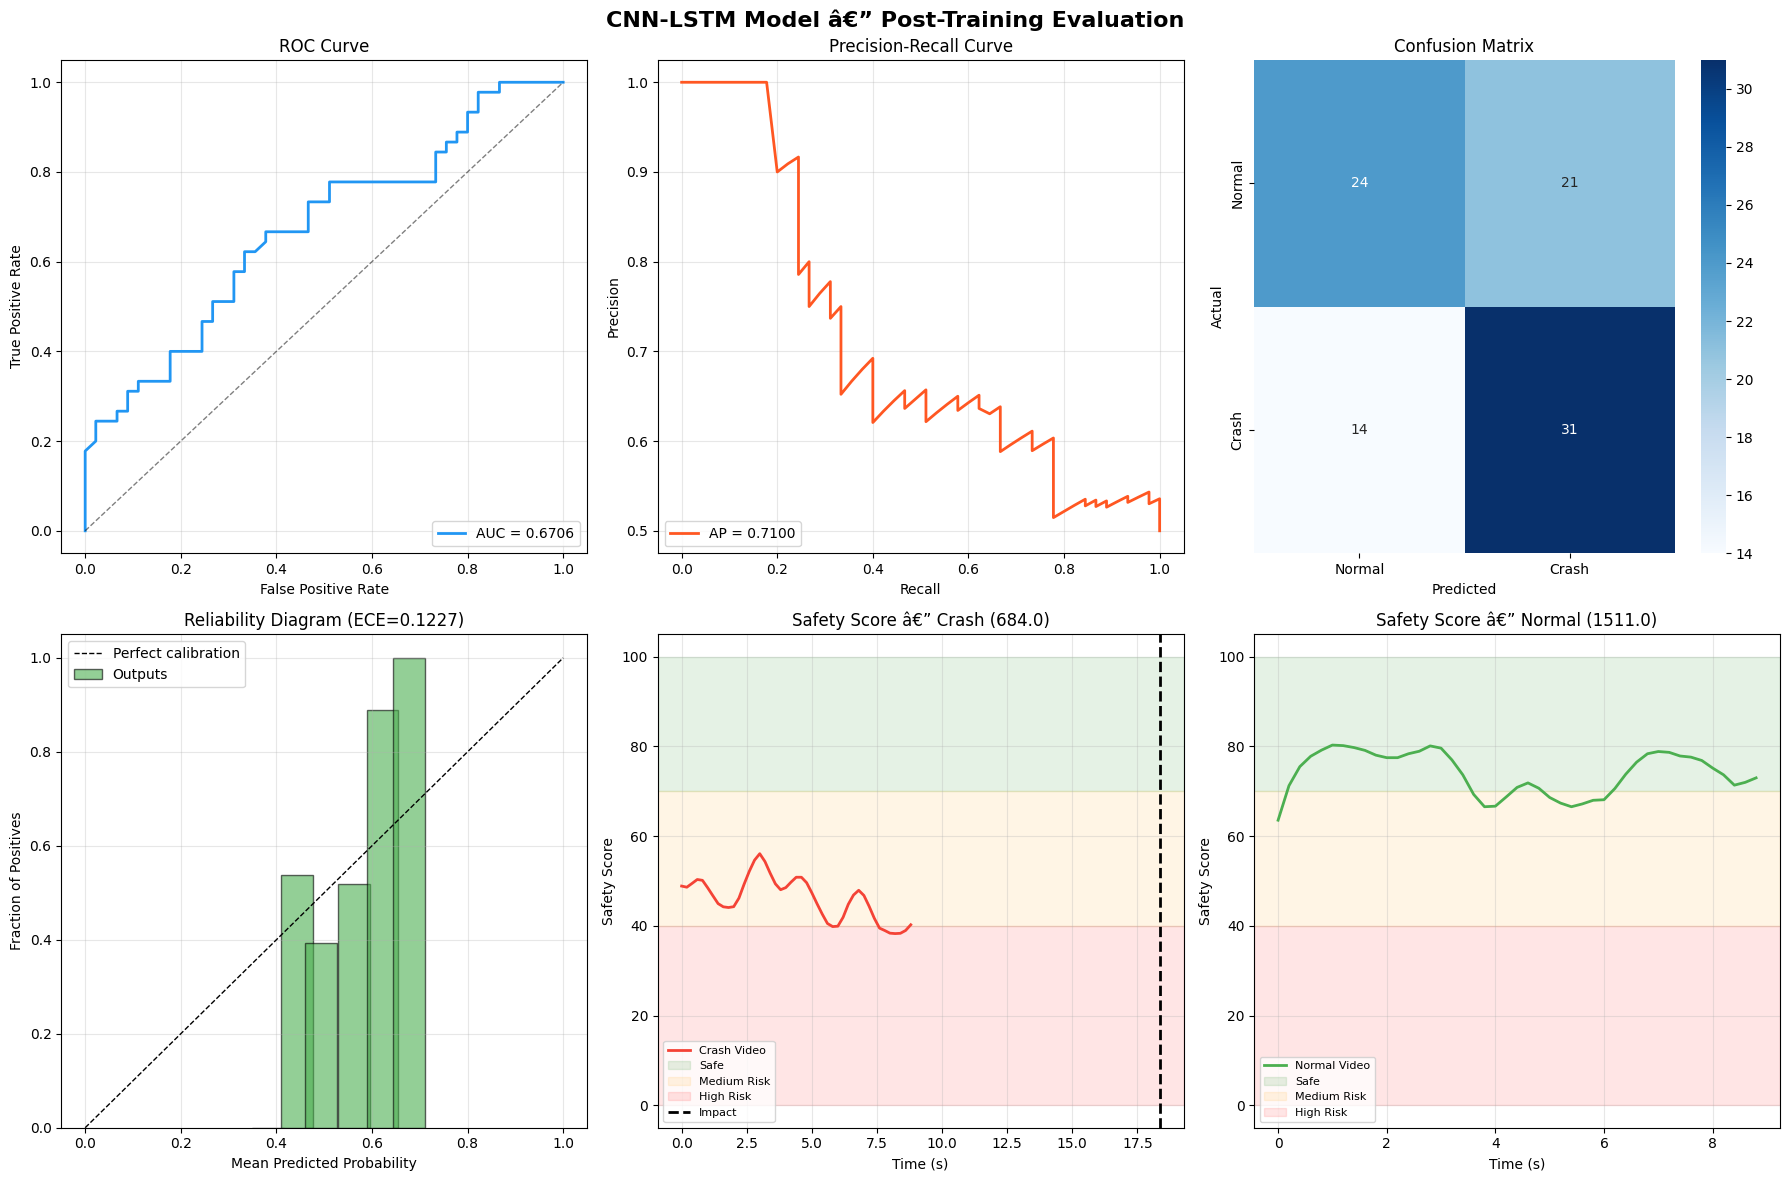

Plots saved.


In [27]:
# Use ensemble (average) predictions from fold 0 for plotting
y_true = test_labels
y_prob = np.array([fold_predictions[0].get(vid, 0.5) for vid in test_df["id"]])
y_logits = np.log(y_prob / (1 - np.clip(y_prob, 1e-7, 1 - 1e-7)))

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
fig.suptitle("CNN-LSTM Model â€” Post-Training Evaluation", fontsize=16, fontweight="bold")

# 1. ROC Curve
ax = axes[0, 0]
fpr, tpr, _ = roc_curve(y_true, y_prob)
auc_val = roc_auc_score(y_true, y_prob)
ax.plot(fpr, tpr, color="#2196F3", lw=2, label=f"AUC = {auc_val:.4f}")
ax.plot([0, 1], [0, 1], "k--", lw=1, alpha=0.5)
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curve")
ax.legend(loc="lower right")
ax.grid(alpha=0.3)

# 2. Precision-Recall Curve
ax = axes[0, 1]
precision_arr, recall_arr, _ = precision_recall_curve(y_true, y_prob)
ap_val = average_precision_score(y_true, y_prob)
ax.plot(recall_arr, precision_arr, color="#FF5722", lw=2, label=f"AP = {ap_val:.4f}")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision-Recall Curve")
ax.legend(loc="lower left")
ax.grid(alpha=0.3)

# 3. Confusion Matrix
ax = axes[0, 2]
y_pred = (y_prob >= 0.5).astype(int)
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
            xticklabels=["Normal", "Crash"], yticklabels=["Normal", "Crash"])
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title("Confusion Matrix")

# 4. Reliability Diagram (Calibration Curve)
ax = axes[1, 0]
ece_before, bin_data = compute_ece(y_true, y_prob, CONFIG["ece_bins"])
bin_centers = [b["avg_confidence"] for b in bin_data if b["count"] > 0]
bin_accs = [b["avg_accuracy"] for b in bin_data if b["count"] > 0]
ax.bar(bin_centers, bin_accs, width=1.0/CONFIG["ece_bins"], alpha=0.6, color="#4CAF50", edgecolor="black", label="Outputs")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Perfect calibration")
ax.set_xlabel("Mean Predicted Probability")
ax.set_ylabel("Fraction of Positives")
ax.set_title(f"Reliability Diagram (ECE={ece_before:.4f})")
ax.legend()
ax.grid(alpha=0.3)

# 5. Safety Score Trace â€” Crash Video
ax = axes[1, 1]
if sample_crash_trace is not None:
    scores = sample_crash_trace["safety_scores"]
    t_axis = np.arange(len(scores)) / CONFIG["sample_fps"]
    ax.plot(t_axis, scores, color="#F44336", lw=2, label="Crash Video")
    ax.axhspan(70, 100, alpha=0.1, color="green", label="Safe")
    ax.axhspan(40, 70, alpha=0.1, color="orange", label="Medium Risk")
    ax.axhspan(0, 40, alpha=0.1, color="red", label="High Risk")
    if sample_crash_trace["time_of_event"] is not None:
        ax.axvline(x=float(sample_crash_trace["time_of_event"]), color="black",
                   linestyle="--", lw=2, label="Impact")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Safety Score")
    ax.set_title(f"Safety Score â€” Crash ({sample_crash_trace['video_id']})")
    ax.set_ylim(-5, 105)
    ax.legend(loc="lower left", fontsize=8)
    ax.grid(alpha=0.3)

# 6. Safety Score Trace â€” Normal Video
ax = axes[1, 2]
if sample_normal_trace is not None:
    scores = sample_normal_trace["safety_scores"]
    t_axis = np.arange(len(scores)) / CONFIG["sample_fps"]
    ax.plot(t_axis, scores, color="#4CAF50", lw=2, label="Normal Video")
    ax.axhspan(70, 100, alpha=0.1, color="green", label="Safe")
    ax.axhspan(40, 70, alpha=0.1, color="orange", label="Medium Risk")
    ax.axhspan(0, 40, alpha=0.1, color="red", label="High Risk")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Safety Score")
    ax.set_title(f"Safety Score â€” Normal ({sample_normal_trace['video_id']})")
    ax.set_ylim(-5, 105)
    ax.legend(loc="lower left", fontsize=8)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(CONFIG["results_dir"], "evaluation_plots.png"), dpi=150, bbox_inches="tight")
plt.show()
print("Plots saved.")

## 19. Final Summary Table

In [28]:
# ============================================================
# COMPREHENSIVE RESULTS SUMMARY
# ============================================================

print(f"\n{'='*80}")
print("CNN-LSTM MODEL â€” FINAL RESULTS SUMMARY")
print(f"{'='*80}")
print(f"Model: ResNet18 + LSTM (hidden={CONFIG['lstm_hidden_size']}, layers={CONFIG['lstm_num_layers']})")
print(f"Input: {CONFIG['sequence_length']} frames @ {CONFIG['sample_fps']} FPS ({CONFIG['sequence_length']/CONFIG['sample_fps']:.1f}s clips)")
print(f"Model Size: {size_mb:.2f} MB")
print(f"Parameters: {total_params:,} (trainable: {trainable_params:,})")
print(f"Inference Speed: {fps:.1f} clips/s ({effective_fps:.1f} frames/s)")
print()

# Per-fold CV results
print("Cross-Validation Results:")
for r in all_fold_results:
    print(f"  Fold {r['fold']}: Val AUC = {r['best_val_auc']:.4f} (best epoch: {r['best_epoch']})")
aucs = [r["best_val_auc"] for r in all_fold_results]
print(f"  Mean Val AUC: {np.mean(aucs):.4f} +/- {np.std(aucs):.4f}")
print()

# Test set results
print("Held-Out Test Set Results (Mean +/- Std, 95% CI):")
print(f"{'Metric':25s} | {'Raw':40s} | {'TTA':40s}")
print("-" * 110)
for metric_name in ["accuracy", "precision", "recall", "f1", "roc_auc", "average_precision", "fpr_at_95tpr"]:
    raw_vals = [m[metric_name] for m in fold_metrics_raw]
    tta_vals = [m[metric_name] for m in fold_metrics_tta]
    mean_r, std_r = np.mean(raw_vals), np.std(raw_vals)
    mean_t, std_t = np.mean(tta_vals), np.std(tta_vals)
    ci_r = 1.96 * std_r / np.sqrt(len(raw_vals))
    ci_t = 1.96 * std_t / np.sqrt(len(tta_vals))
    print(f"{metric_name:25s} | {mean_r:.4f} +/- {std_r:.4f} [{mean_r-ci_r:.4f},{mean_r+ci_r:.4f}] | "
          f"{mean_t:.4f} +/- {std_t:.4f} [{mean_t-ci_t:.4f},{mean_t+ci_t:.4f}]")

print(f"\nCalibration:")
print(f"  ECE (before temp scaling): {np.mean(fold_ece_before):.4f} +/- {np.std(fold_ece_before):.4f}")
print(f"  ECE (after temp scaling):  {np.mean(fold_ece_after):.4f} +/- {np.std(fold_ece_after):.4f}")
print(f"  Temperature:               {np.mean(fold_temperatures):.3f} +/- {np.std(fold_temperatures):.3f}")

print(f"\nSafety Metrics:")
if tta_values:
    print(f"  Mean TTA: {np.mean(tta_values):.2f}s +/- {np.std(tta_values):.2f}s")
if early_detections:
    print(f"  Early Detection Rate (>=2s): {np.mean(early_detections)*100:.1f}%")
print(f"  Score Stability: {np.mean(all_stabilities):.2f} +/- {np.std(all_stabilities):.2f}")

print(f"\nOutput files:")
print(f"  Checkpoints: {CONFIG['checkpoint_dir']}/seed42_fold{{0,1,2}}.pth")
print(f"  CV Scores: {os.path.join(CONFIG['results_dir'], 'cv_scores.csv')}")
print(f"  Config: {os.path.join(CONFIG['results_dir'], 'config.json')}")
print(f"  Shared splits: {CONFIG['shared_splits_path']}")
print(f"  Plots: {os.path.join(CONFIG['results_dir'], 'evaluation_plots.png')}")


CNN-LSTM MODEL â€” FINAL RESULTS SUMMARY


KeyError: 'lstm_hidden_size'

## 20. Streaming Inference Demo

Simulates real-time dashcam inference on a video file. Processes frames in a sliding-window fashion as if they were arriving from a live camera feed, producing a **real-time safety score overlay** with color-coded risk bands.

This is the function you would adapt for a real deployment:
- Replace `VideoReader` with your camera/RTSP frame source
- The `StreamingCrashDetector` maintains an internal frame buffer and outputs a safety score every time a full window (16 frames) is available

In [ ]:
class StreamingCrashDetector:
    """
    Streaming crash detector that processes frames one-at-a-time,
    mimicking a live camera feed. Maintains an internal ring buffer
    and produces a safety score whenever a full window is available.
    
    Usage (real deployment):
        detector = StreamingCrashDetector(model, config, device)
        for frame in camera_stream:
            result = detector.push_frame(frame)  # frame: (H, W, C) uint8 numpy
            if result is not None:
                print(f"Safety Score: {result['safety_score']:.1f}")
    """
    
    def __init__(self, model, config, device):
        self.model = model
        self.model.eval()
        self.config = config
        self.device = device
        self.seq_len = config["sequence_length"]
        self.img_size = config["img_size"]
        self.crop_frac = config["crop_top_fraction"]
        self.ema_alpha = config["ema_alpha"]
        
        # Ring buffer for incoming frames (stores preprocessed tensors)
        self.frame_buffer = []
        self.frame_count = 0
        
        # EMA state
        self.prev_smoothed_prob = config["ema_init"]
        
        # History for plotting
        self.history = []
    
    def _preprocess_frame(self, frame):
        """Preprocess a single (H, W, C) uint8 numpy frame to normalized tensor."""
        # Crop top (watermark removal)
        h = frame.shape[0]
        crop_h = int(h * self.crop_frac)
        frame = frame[crop_h:, :, :]
        
        # To tensor, resize, normalize
        t = torch.from_numpy(frame).permute(2, 0, 1).float() / 255.0
        t = F.interpolate(
            t.unsqueeze(0),
            size=(self.img_size, self.img_size),
            mode="bilinear", align_corners=False,
        ).squeeze(0)
        t = normalize_transform(t)
        return t
    
    @torch.no_grad()
    def push_frame(self, frame):
        """
        Push a single frame (H, W, C) uint8 numpy array.
        Returns a result dict when a full window is available, else None.
        """
        processed = self._preprocess_frame(frame)
        self.frame_buffer.append(processed)
        self.frame_count += 1
        
        # Only predict when we have a full window
        if len(self.frame_buffer) < self.seq_len:
            return None
        
        # Take the last seq_len frames
        window = self.frame_buffer[-self.seq_len:]
        clip = torch.stack(window, dim=0).unsqueeze(0).to(self.device)  # (1, T, C, H, W)
        
        with autocast(enabled=self.config["use_amp"]):
            logit = self.model(clip)
        raw_prob = torch.sigmoid(logit.squeeze()).cpu().item()
        
        # EMA smoothing
        smoothed_prob = self.ema_alpha * raw_prob + (1 - self.ema_alpha) * self.prev_smoothed_prob
        self.prev_smoothed_prob = smoothed_prob
        
        # Safety score
        safety_score = max(0, min(100, 100.0 - smoothed_prob * 100.0))
        
        # Risk band
        if safety_score >= 70:
            risk_band = "SAFE"
        elif safety_score >= 40:
            risk_band = "MEDIUM RISK"
        else:
            risk_band = "HIGH RISK"
        
        result = {
            "frame_idx": self.frame_count,
            "raw_prob": raw_prob,
            "smoothed_prob": smoothed_prob,
            "safety_score": safety_score,
            "risk_band": risk_band,
        }
        self.history.append(result)
        
        # Keep buffer bounded (only need last seq_len frames)
        if len(self.frame_buffer) > self.seq_len:
            self.frame_buffer = self.frame_buffer[-self.seq_len:]
        
        return result
    
    def reset(self):
        """Reset state for a new video/stream."""
        self.frame_buffer = []
        self.frame_count = 0
        self.prev_smoothed_prob = self.config["ema_init"]
        self.history = []


def run_streaming_demo(video_path, model, config, device, stride_frames=1, display_every=4):
    """
    Simulate streaming inference on a video file.
    Reads frames at sample_fps, feeds them one-by-one to the detector,
    and produces a real-time safety score timeline + overlay frames.
    
    Args:
        video_path: path to .mp4 file
        model: trained CNNLSTM model (already on device, eval mode)
        config: CONFIG dict
        device: torch device
        stride_frames: push every Nth sampled frame (1 = every frame at 5fps)
        display_every: show an overlay frame every N predictions
    
    Returns:
        detector: StreamingCrashDetector with full history
        overlay_frames: list of (frame_rgb, result) tuples for visualization
    """
    detector = StreamingCrashDetector(model, config, device)
    
    vr = VideoReader(video_path, ctx=cpu(0))
    video_fps = vr.get_avg_fps()
    total_frames = len(vr)
    if video_fps <= 0:
        video_fps = 30.0
    
    step = max(1, round(video_fps / config["sample_fps"]))
    sampled_indices = list(range(0, total_frames, step))
    
    overlay_frames = []
    
    print(f"Streaming demo: {len(sampled_indices)} frames at {config['sample_fps']} FPS "
          f"(original: {total_frames} frames at {video_fps:.1f} FPS)")
    
    for i, frame_idx in enumerate(tqdm(sampled_indices, desc="Streaming")):
        if i % stride_frames != 0:
            continue
        
        # Simulate receiving a single frame from camera
        frame = vr[frame_idx].asnumpy()  # (H, W, C) uint8
        
        result = detector.push_frame(frame)
        
        if result is not None and len(detector.history) % display_every == 0:
            overlay_frames.append((frame.copy(), result))
    
    del vr
    print(f"Streaming complete: {len(detector.history)} predictions, "
          f"{len(overlay_frames)} overlay frames saved.")
    
    return detector, overlay_frames


def plot_streaming_results(detector, video_path, time_of_event=None):
    """Plot the streaming safety score timeline with risk bands."""
    if not detector.history:
        print("No predictions to plot.")
        return
    
    history = detector.history
    sample_fps = detector.config["sample_fps"]
    seq_len = detector.config["sequence_length"]
    
    # X-axis: time in seconds (accounting for the initial buffer fill)
    times = [(h["frame_idx"] / sample_fps) for h in history]
    scores = [h["safety_score"] for h in history]
    raw_probs = [h["raw_prob"] for h in history]
    smoothed_probs = [h["smoothed_prob"] for h in history]
    
    fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
    fig.suptitle(f"Streaming Inference Demo — {os.path.basename(video_path)}", 
                 fontsize=14, fontweight="bold")
    
    # --- Top: Safety Score ---
    ax = axes[0]
    ax.fill_between(times, 70, 100, alpha=0.15, color="green", label="Safe (70-100)")
    ax.fill_between(times, 40, 70, alpha=0.15, color="orange", label="Medium Risk (40-70)")
    ax.fill_between(times, 0, 40, alpha=0.15, color="red", label="High Risk (0-40)")
    ax.plot(times, scores, color="#1565C0", lw=2, label="Safety Score")
    if time_of_event is not None:
        ax.axvline(x=float(time_of_event), color="black", ls="--", lw=2, label="Impact")
    ax.set_ylabel("Safety Score")
    ax.set_ylim(-5, 105)
    ax.legend(loc="lower left", fontsize=8)
    ax.grid(alpha=0.3)
    
    # --- Bottom: Raw vs Smoothed crash probability ---
    ax = axes[1]
    ax.plot(times, raw_probs, color="#BDBDBD", lw=1, alpha=0.7, label="Raw P(crash)")
    ax.plot(times, smoothed_probs, color="#F44336", lw=2, label="EMA Smoothed P(crash)")
    ax.axhline(y=0.5, color="black", ls=":", lw=1, alpha=0.5, label="Threshold (0.5)")
    if time_of_event is not None:
        ax.axvline(x=float(time_of_event), color="black", ls="--", lw=2, label="Impact")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Crash Probability")
    ax.set_ylim(-0.05, 1.05)
    ax.legend(loc="upper left", fontsize=8)
    ax.grid(alpha=0.3)
    
    plt.tight_layout()
    
    # Save
    save_path = os.path.join(detector.config["results_dir"], "streaming_demo.png")
    plt.savefig(save_path, dpi=150, bbox_inches="tight")
    print(f"Saved to {save_path}")
    plt.show()


def show_overlay_grid(overlay_frames, cols=4, figsize=(16, 10)):
    """Show a grid of frames with safety score overlays."""
    n = min(len(overlay_frames), cols * 3)  # Max 3 rows
    if n == 0:
        print("No overlay frames.")
        return
    
    rows = math.ceil(n / cols)
    fig, axes = plt.subplots(rows, cols, figsize=figsize)
    if rows == 1:
        axes = [axes]
    axes = np.array(axes).flatten()
    
    for i in range(n):
        frame, result = overlay_frames[i]
        ax = axes[i]
        ax.imshow(frame)
        
        score = result["safety_score"]
        band = result["risk_band"]
        color = "green" if score >= 70 else ("orange" if score >= 40 else "red")
        
        ax.set_title(f"Score: {score:.0f} [{band}]\nt={result['frame_idx']/5:.1f}s",
                     fontsize=9, color=color, fontweight="bold")
        ax.axis("off")
    
    for i in range(n, len(axes)):
        axes[i].axis("off")
    
    plt.suptitle("Streaming Demo — Frame Snapshots", fontsize=13, fontweight="bold")
    plt.tight_layout()
    
    save_path = os.path.join(CONFIG["results_dir"], "streaming_overlay_grid.png")
    plt.savefig(save_path, dpi=150, bbox_inches="tight")
    print(f"Saved to {save_path}")
    plt.show()


print("Streaming inference classes and demo functions defined.")

In [ ]:
# ============================================================
# RUN STREAMING DEMO ON ONE CRASH + ONE NORMAL VIDEO
# ============================================================

# Load best model from fold 0
demo_model = load_best_model(0, CONFIG, DEVICE)

# Pick one crash and one normal video from the test set
demo_crash_row = test_df[test_df["target"] == 1].iloc[0]
demo_normal_row = test_df[test_df["target"] == 0].iloc[0]

# --- Crash video demo ---
crash_path = os.path.join(CONFIG["train_video_dir"], f"{int(demo_crash_row['id']):05d}.mp4")
print(f"\n{'='*60}")
print(f"CRASH VIDEO: {demo_crash_row['id']} (event at {demo_crash_row.get('time_of_event', '?')}s)")
print(f"{'='*60}")

crash_detector, crash_overlays = run_streaming_demo(
    crash_path, demo_model, CONFIG, DEVICE, stride_frames=1, display_every=4
)
plot_streaming_results(crash_detector, crash_path, time_of_event=demo_crash_row.get("time_of_event", None))
if crash_overlays:
    show_overlay_grid(crash_overlays)

# --- Normal video demo ---
normal_path = os.path.join(CONFIG["train_video_dir"], f"{int(demo_normal_row['id']):05d}.mp4")
print(f"\n{'='*60}")
print(f"NORMAL VIDEO: {demo_normal_row['id']}")
print(f"{'='*60}")

normal_detector, normal_overlays = run_streaming_demo(
    normal_path, demo_model, CONFIG, DEVICE, stride_frames=1, display_every=4
)
plot_streaming_results(normal_detector, normal_path)
if normal_overlays:
    show_overlay_grid(normal_overlays)

# Print summary
print(f"\n{'='*60}")
print("STREAMING DEMO SUMMARY")
print(f"{'='*60}")
crash_scores = [h["safety_score"] for h in crash_detector.history]
normal_scores = [h["safety_score"] for h in normal_detector.history]
print(f"Crash video  — Min safety: {min(crash_scores):.0f}, Mean: {np.mean(crash_scores):.0f}, "
      f"Time in HIGH RISK: {sum(1 for s in crash_scores if s < 40)/len(crash_scores)*100:.0f}%")
print(f"Normal video — Min safety: {min(normal_scores):.0f}, Mean: {np.mean(normal_scores):.0f}, "
      f"Time in HIGH RISK: {sum(1 for s in normal_scores if s < 40)/len(normal_scores)*100:.0f}%")

del demo_model
torch.cuda.empty_cache()

## 21. Save All Checkpoints & Results to Output

Saves all checkpoints, predictions cache, results, and splits to  so they appear in the **Output** panel and can be uploaded as a dataset for the next run.

In [ ]:
import os, shutil, glob

print("Saving all outputs...")
print("=" * 60)

# 1. Checkpoints
ckpt_files = glob.glob("/kaggle/working/checkpoints/*.pth")
print("\n[1] Checkpoints (" + str(len(ckpt_files)) + " files):")
for f in sorted(ckpt_files):
    size_mb = os.path.getsize(f) / 1e6
    print("    " + os.path.basename(f) + "  (" + str(round(size_mb,1)) + " MB)")

# 2. Predictions cache
pred_cache = "/kaggle/working/results/fold_predictions_cache.json"
if os.path.exists(pred_cache):
    size_mb = os.path.getsize(pred_cache) / 1e6
    print("\n[2] fold_predictions_cache.json  (" + str(round(size_mb,2)) + " MB)  FOUND")
else:
    print("\n[2] fold_predictions_cache.json  NOT FOUND — inference incomplete")

# 3. Results folder
results_files = glob.glob("/kaggle/working/results/*")
print("\n[3] Results (" + str(len(results_files)) + " files):")
for f in sorted(results_files):
    size_mb = os.path.getsize(f) / 1e6
    print("    " + os.path.basename(f) + "  (" + str(round(size_mb,2)) + " MB)")

# 4. Shared splits
splits_path = "/kaggle/working/shared_data_splits.json"
if os.path.exists(splits_path):
    print("\n[4] shared_data_splits.json  FOUND")
else:
    print("\n[4] shared_data_splits.json  NOT FOUND")

print("\n" + "=" * 60)
print("NEXT RUN INSTRUCTIONS:")
print("  1. kaggle.com -> Datasets -> New Dataset")
print("  2. Upload: checkpoints/, results/, shared_data_splits.json")
print("  3. Name it: mobinet-checkpoint")
print("  4. Add as input in next notebook session")
print("  5. Cell 5 auto-restores everything and skips training!")
print("=" * 60)
print("\nAll outputs in /kaggle/working/ visible in Output panel. Done!")


In [ ]:
# Final cleanup
import gc
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
print("\nTraining complete. Notebook finished successfully.")
